# CañaScan — Pipeline de Detección de Enfermedades en Caña de Azúcar

## Arquitectura del sistema
- **Modelo de Identificación de Hoja** (YOLOv8n): Detecta si hay una hoja de caña en la imagen. Actúa como filtro para evitar falsos positivos.
- **Modelo de Enfermedades** (YOLOv8m): Clasifica la enfermedad presente en la hoja detectada.

## Datasets
- Modelo Enfermedades: `Sugarcane Modelo.v8-datasetdefinitivo_v2.yolov8` 7 clases, ~400 imágenes/clase, split 70/20/10
- Modelo Hoja: `sugarcane-leaf-detector.v1-dataset_hojacana.yolov8r` 1 clase `hoja_cana`, ~3933 train + 400 negativos

## Clases del Modelo de Enfermedades
| ID | Clase | Etiquetado |
|---|---|---|
| 0 | Amarillamiento | Hoja completa |
| 1 | CogolleroAvanzado | Zona afectada |
| 2 | CogolleroInicial | Zona afectada |
| 3 | Mosaico | Hoja completa |
| 4 | PobredumbreRoja | Bbox largo centro de la hoja |
| 5 | Roya | Hoja completa |
| 6 | Saludable | Hoja completa |

# Modelo de Enfermedades (YOLOv8m)

In [ ]:
from ultralytics import YOLO

model = YOLO('yolov8m.pt')

results = model.train(
    data='/content/dataset_local/data.yaml',
    epochs=60,
    imgsz=640,
    batch=8,
    patience=0,
    save_period=1,
    device='cuda',
    pretrained=True,
    optimizer='SGD',
    lr0=0.001,
    lrf=0.01,
    cos_lr=True,
    box=8.0,
    cls=0.75,
    momentum=0.937,
    weight_decay=0.0005,
    workers=2,
    hsv_h=0.02,
    hsv_s=0.8,
    hsv_v=0.5,
    scale=0.3,
    translate=0.15,
    copy_paste=0.1,
    project='/content/drive/MyDrive/9no Ciclo/Taller 2',
    name='Modelo_DEF5',
    exist_ok=True
)

print(f"Entrenamiento completado. Resultados en: {results.save_dir}")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.80 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=8.0, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.75, cls_pw=0.0, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/dataset_local/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import shutil, os

dest_base = '/content/drive/MyDrive/9no Ciclo/Taller 2/Sugarcane Modelo.v8-datasetdefinitivo_v2.yolov8'

if os.path.exists('/content/dataset_local'):
    shutil.rmtree('/content/dataset_local')

shutil.copytree(dest_base, '/content/dataset_local')
print("Dataset copiado")
print(f"Train: {len(os.listdir('/content/dataset_local/train/images'))} imágenes")
print(f"Valid: {len(os.listdir('/content/dataset_local/valid/images'))} imágenes")
print(f"Test: {len(os.listdir('/content/dataset_local/test/images'))} imágenes")

Mounted at /content/drive
Dataset copiado
Train: 5307 imágenes
Valid: 505 imágenes
Test: 253 imágenes


In [ ]:
!pip install ultralytics -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.0/41.0 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 64.1 MB/s eta 0:00:00


=== MÉTRICAS DEL MEJOR MODELO — Época 35 de 60 ===
mAP50:                0.9101
mAP50-95:             0.7527
Precision:            0.9011
Recall:               0.9074
Box Loss (train):     0.5123
Cls Loss (train):     0.6373
Box Loss (val):       0.7154
Cls Loss (val):       0.7465


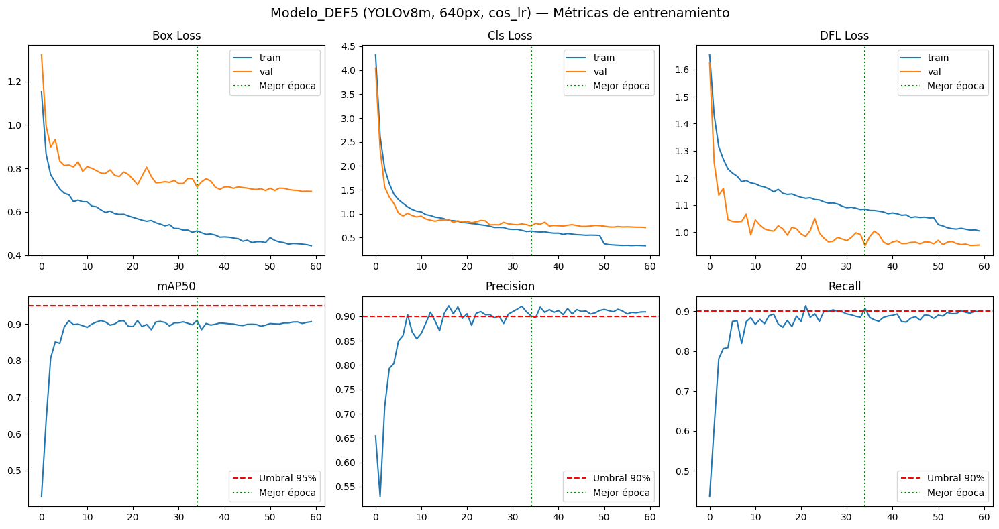


Gráfica guardada en Drive


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

results_path = '/content/drive/MyDrive/9no Ciclo/Taller 2/Modelo_DEF5'

df = pd.read_csv(f'{results_path}/results.csv')
df.columns = df.columns.str.strip()

mejor_epoca = df['metrics/mAP50(B)'].idxmax()

print(f"=== MÉTRICAS DEL MEJOR MODELO — Época {mejor_epoca + 1} de {len(df)} ===")
print(f"mAP50:                {df['metrics/mAP50(B)'].iloc[mejor_epoca]:.4f}")
print(f"mAP50-95:             {df['metrics/mAP50-95(B)'].iloc[mejor_epoca]:.4f}")
print(f"Precision:            {df['metrics/precision(B)'].iloc[mejor_epoca]:.4f}")
print(f"Recall:               {df['metrics/recall(B)'].iloc[mejor_epoca]:.4f}")
print(f"Box Loss (train):     {df['train/box_loss'].iloc[mejor_epoca]:.4f}")
print(f"Cls Loss (train):     {df['train/cls_loss'].iloc[mejor_epoca]:.4f}")
print(f"Box Loss (val):       {df['val/box_loss'].iloc[mejor_epoca]:.4f}")
print(f"Cls Loss (val):       {df['val/cls_loss'].iloc[mejor_epoca]:.4f}")

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Modelo_DEF5 (YOLOv8m, 640px, cos_lr) — Métricas de entrenamiento', fontsize=14)

axes[0,0].plot(df['train/box_loss'], label='train')
axes[0,0].plot(df['val/box_loss'], label='val')
axes[0,0].axvline(x=mejor_epoca, color='g', linestyle=':', label='Mejor época')
axes[0,0].set_title('Box Loss')
axes[0,0].legend()

axes[0,1].plot(df['train/cls_loss'], label='train')
axes[0,1].plot(df['val/cls_loss'], label='val')
axes[0,1].axvline(x=mejor_epoca, color='g', linestyle=':', label='Mejor época')
axes[0,1].set_title('Cls Loss')
axes[0,1].legend()

axes[0,2].plot(df['train/dfl_loss'], label='train')
axes[0,2].plot(df['val/dfl_loss'], label='val')
axes[0,2].axvline(x=mejor_epoca, color='g', linestyle=':', label='Mejor época')
axes[0,2].set_title('DFL Loss')
axes[0,2].legend()

axes[1,0].plot(df['metrics/mAP50(B)'])
axes[1,0].axhline(y=0.95, color='r', linestyle='--', label='Umbral 95%')
axes[1,0].axvline(x=mejor_epoca, color='g', linestyle=':', label='Mejor época')
axes[1,0].set_title('mAP50')
axes[1,0].legend()

axes[1,1].plot(df['metrics/precision(B)'])
axes[1,1].axhline(y=0.90, color='r', linestyle='--', label='Umbral 90%')
axes[1,1].axvline(x=mejor_epoca, color='g', linestyle=':', label='Mejor época')
axes[1,1].set_title('Precision')
axes[1,1].legend()

axes[1,2].plot(df['metrics/recall(B)'])
axes[1,2].axhline(y=0.90, color='r', linestyle='--', label='Umbral 90%')
axes[1,2].axvline(x=mejor_epoca, color='g', linestyle=':', label='Mejor época')
axes[1,2].set_title('Recall')
axes[1,2].legend()

plt.tight_layout()
plt.savefig(f'{results_path}/metricas_DEF5.png', dpi=150)
plt.show()
print("\nGráfica guardada en Drive")

In [ ]:
import pandas as pd

results_path = '/content/drive/MyDrive/9no Ciclo/Taller 2/Modelo_DEF5'

df = pd.read_csv(f'{results_path}/results.csv')
df.columns = df.columns.str.strip()

mejor_epoca = df['metrics/mAP50(B)'].idxmax()

print(f"Mejor época según CSV: {mejor_epoca + 1}")
print(f"Checkpoint correspondiente: epoch{mejor_epoca}.pt")
print(f"mAP50 en validación: {df['metrics/mAP50(B)'].iloc[mejor_epoca]:.4f}")

Mejor época según CSV: 35
Checkpoint correspondiente: epoch34.pt
mAP50 en validación: 0.9101


In [ ]:
from ultralytics import YOLO

mejor_checkpoint = f'{results_path}/weights/epoch{mejor_epoca}.pt'
print(f"Cargando checkpoint de época {mejor_epoca + 1}: {mejor_checkpoint}")

model = YOLO(mejor_checkpoint)

metrics = model.val(
    data='/content/dataset_local/data.yaml',
    split='test',
    imgsz=640,
    conf=0.15,
    plots=True,
    save_json=False,
)

print(f"\nResultados guardados en: {metrics.save_dir}")
print(f"mAP50 global: {metrics.box.map50:.4f}")
print(f"mAP50-95 global: {metrics.box.map:.4f}")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Cargando checkpoint de época 35: /content/drive/MyDrive/9no Ciclo/Taller 2/Modelo_DEF5/weights/epoch34.pt
Ultralytics 8.4.80 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
Model summary (fused): 93 layers, 25,843,813 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1408.0±431.8 MB/s, size: 46.5 KB)
val: Scanning /content/dataset_local/test/labels... 253 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 253/253 1.5Kit/s 0.2s
val: New cache created: /content/dataset_local/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 4.4it/s 3.6s

In [ ]:
!pip install grad-cam -q

import torch
import numpy as np
import cv2
import os
import random
import matplotlib.pyplot as plt
from ultralytics import YOLO
from pytorch_grad_cam.utils.image import show_cam_on_image

model_path = f'{results_path}/weights/epoch{mejor_epoca}.pt'
print(f"Cargando modelo de época {mejor_epoca + 1}")
model = YOLO(model_path)
torch_model = model.model.cuda()
torch_model.eval()

print("Modelo cargado en GPU")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 141.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Cargando modelo de época 35
Modelo cargado en GPU


In [ ]:
def generar_heatmap(imagen_path, save_path=None, titulo='Mapa de calor'):
    img_bgr = cv2.imread(imagen_path)
    if img_bgr is None:
        print(f'No se pudo leer la imagen: {imagen_path}')
        return

    img_bgr = cv2.resize(img_bgr, (640, 640))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_float = np.float32(img_rgb) / 255.0
    tensor = torch.from_numpy(img_float).permute(2, 0, 1).unsqueeze(0).cuda()

    activaciones = {}
    def hook_fn(module, input, output):
        if isinstance(output, torch.Tensor):
            activaciones['feat'] = output.detach()

    hook = torch_model.model[8].register_forward_hook(hook_fn)

    try:
        with torch.no_grad():
            torch_model(tensor)

        feat = activaciones.get('feat')
        if feat is None:
            print('No se capturaron activaciones')
            return

        heatmap = feat.squeeze(0).mean(dim=0).cpu().numpy()
        heatmap = np.maximum(heatmap, 0)
        heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)
        heatmap = np.power(heatmap, 0.5)
        heatmap = cv2.resize(heatmap, (640, 640))
        heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)
        heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
        heatmap_float = np.float32(heatmap_color) / 255.0
        heatmap_img = 0.4 * img_float + 0.6 * heatmap_float
        heatmap_img = np.clip(heatmap_img, 0, 1)

    except Exception as e:
        print(f'Error generando heatmap: {e}')
        return
    finally:
        hook.remove()

    results = model.predict(imagen_path, conf=0.15, imgsz=640, verbose=False)
    result = results[0]
    img_boxes = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(titulo, fontsize=13)

    axes[0].imshow(img_rgb)
    axes[0].set_title('Imagen original')
    axes[0].axis('off')

    axes[1].imshow(heatmap_img)
    axes[1].set_title('Mapa de calor')
    axes[1].axis('off')

    axes[2].imshow(img_boxes)
    axes[2].set_title('Detecciones YOLOv8m')
    axes[2].axis('off')

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f'Guardado: {save_path}')

    plt.show()

    print('=== DETECCIONES ===')
    if len(result.boxes) == 0:
        print('  No se detectó ninguna enfermedad.')
    else:
        for box in result.boxes:
            clase = model.names[int(box.cls)]
            conf = float(box.conf)
            print(f'  {clase}: {conf:.2%}')

print('Funcion lista')

Funcion lista


Generando heatmaps - 1 imagen aleatoria por clase

Amarillamiento -> yellow-277-_jpeg.rf.56a655fa3cf111ffdafb973027bedbc1.jpg
Guardado: /content/drive/MyDrive/9no Ciclo/Taller 2/Modelo_DEF5/heatmaps/heatmap_Amarillamiento.png


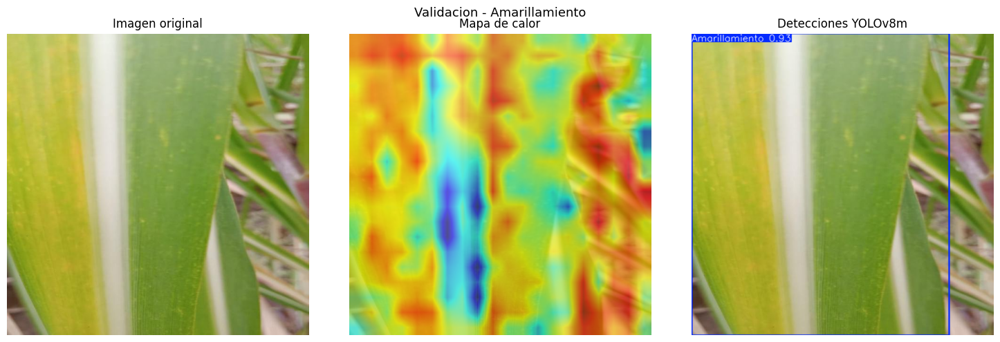

=== DETECCIONES ===
  Amarillamiento: 92.82%
CogolleroAvanzado -> gusano_cogollero-242-_aug_0073_jpg.rf.823da2af7be25fc465806a70cfb688e8.jpg
Guardado: /content/drive/MyDrive/9no Ciclo/Taller 2/Modelo_DEF5/heatmaps/heatmap_CogolleroAvanzado.png


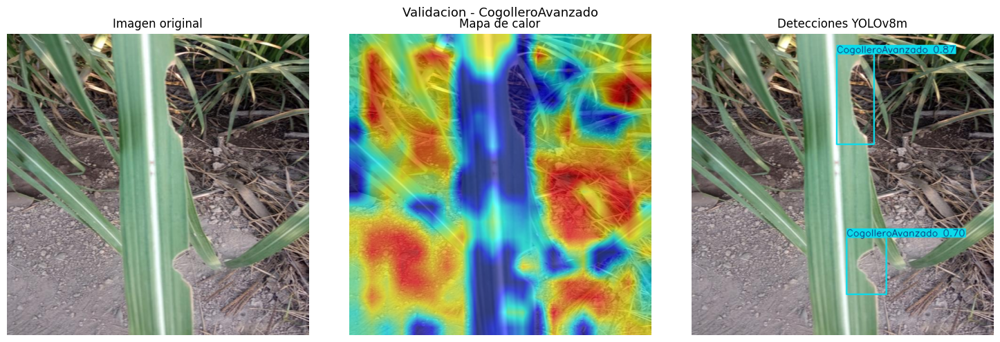

=== DETECCIONES ===
  CogolleroAvanzado: 87.14%
  CogolleroAvanzado: 69.71%
CogolleroInicial -> gusano_cogollero-187-_jpeg.rf.d6f59b7eb4774762932d630728ff289c.jpg
Guardado: /content/drive/MyDrive/9no Ciclo/Taller 2/Modelo_DEF5/heatmaps/heatmap_CogolleroInicial.png


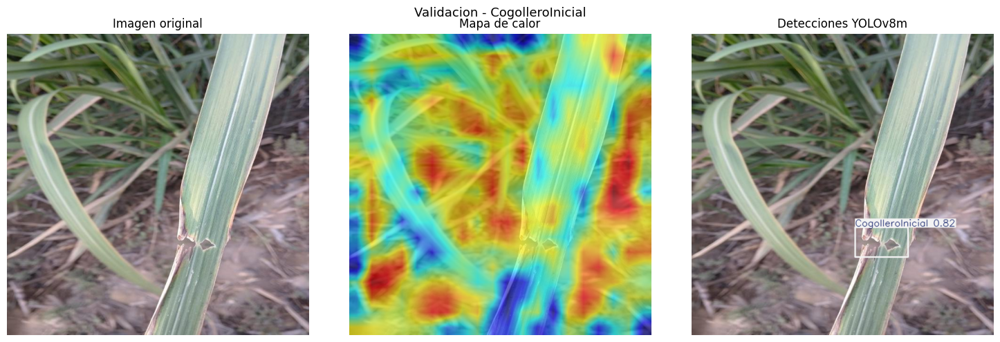

=== DETECCIONES ===
  CogolleroInicial: 81.86%
Mosaico -> mosaic-271-_jpeg.rf.3325bde47e96218cb4c74f91a50609cf.jpg
Guardado: /content/drive/MyDrive/9no Ciclo/Taller 2/Modelo_DEF5/heatmaps/heatmap_Mosaico.png


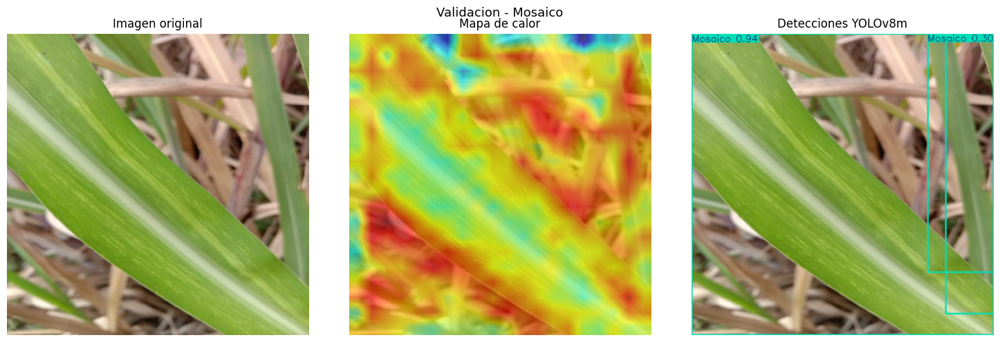

=== DETECCIONES ===
  Mosaico: 93.70%
  Mosaico: 30.21%
  Mosaico: 15.55%
PobredumbreRoja -> redrot-168-_jpeg.rf.8a26addad51ba53e16e9abab84a7c100.jpg
Guardado: /content/drive/MyDrive/9no Ciclo/Taller 2/Modelo_DEF5/heatmaps/heatmap_PobredumbreRoja.png


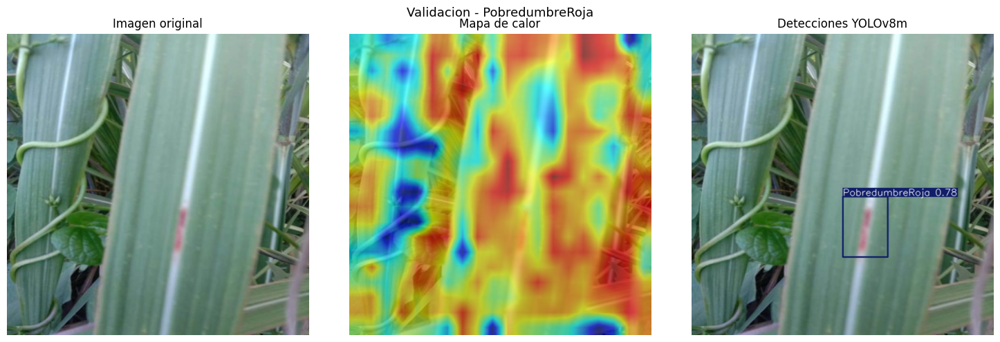

=== DETECCIONES ===
  PobredumbreRoja: 78.40%
Roya -> rust-319-_jpeg.rf.1086436036c469a35147ac4214d67de8.jpg
Guardado: /content/drive/MyDrive/9no Ciclo/Taller 2/Modelo_DEF5/heatmaps/heatmap_Roya.png


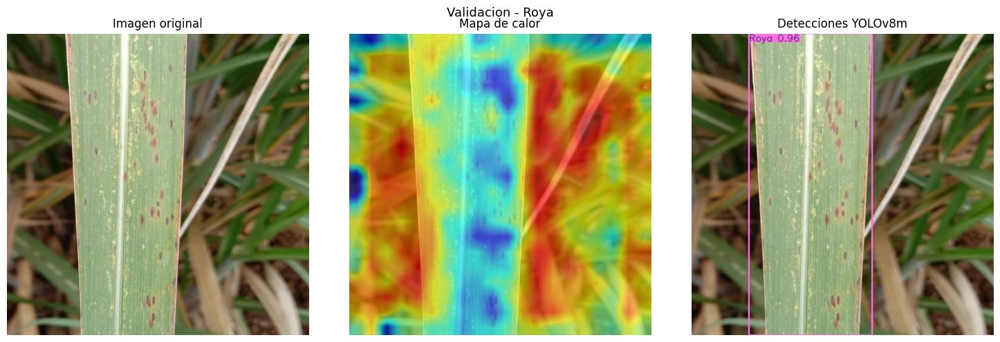

=== DETECCIONES ===
  Roya: 95.93%
Saludable -> healthy-370-_jpeg.rf.7b8201440117fc04056c43f9d7808ee7.jpg
Guardado: /content/drive/MyDrive/9no Ciclo/Taller 2/Modelo_DEF5/heatmaps/heatmap_Saludable.png


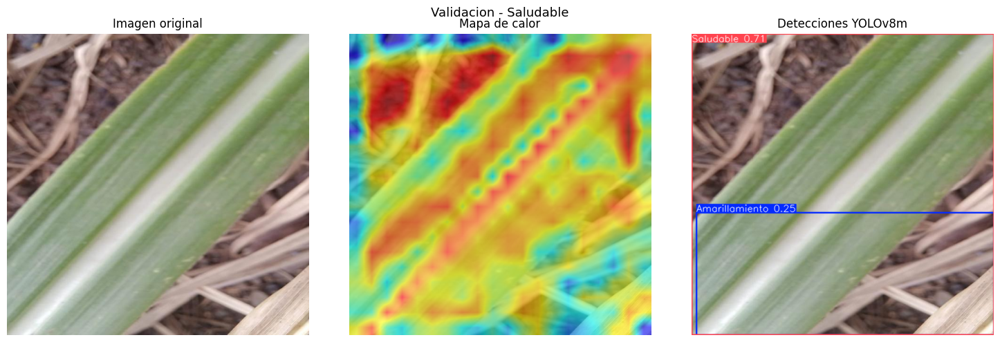

=== DETECCIONES ===
  Saludable: 71.44%
  Amarillamiento: 25.13%

Heatmaps generados para todas las clases.


In [ ]:
import os
import random

dataset_path = '/content/dataset_local/test/images'
labels_path = '/content/dataset_local/test/labels'
carpeta_salida = '/content/drive/MyDrive/9no Ciclo/Taller 2/Modelo_DEF5/heatmaps'
os.makedirs(carpeta_salida, exist_ok=True)

extensiones = {'.jpg', '.jpeg', '.png'}

clases = ['Amarillamiento', 'CogolleroAvanzado', 'CogolleroInicial',
          'Mosaico', 'PobredumbreRoja', 'Roya', 'Saludable']

imagenes_por_clase = {c: [] for c in clases}

for img_file in os.listdir(dataset_path):
    if os.path.splitext(img_file)[1].lower() not in extensiones:
        continue
    label_file = os.path.splitext(img_file)[0] + '.txt'
    label_path = os.path.join(labels_path, label_file)
    if not os.path.exists(label_path):
        continue
    with open(label_path, 'r') as f:
        primera_linea = f.readline().strip()
        if not primera_linea:
            continue
        class_id = int(primera_linea.split()[0])
        nombre_clase = clases[class_id]
        imagenes_por_clase[nombre_clase].append(img_file)

random.seed(42)

print('Generando heatmaps - 1 imagen aleatoria por clase\n')

for nombre_clase in clases:
    imagenes_clase = imagenes_por_clase[nombre_clase]
    if not imagenes_clase:
        print(f'No se encontraron imagenes para: {nombre_clase}')
        continue

    seleccionada = random.choice(imagenes_clase)
    ruta = os.path.join(dataset_path, seleccionada)
    salida = os.path.join(carpeta_salida, f'heatmap_{nombre_clase}.png')

    print(f'{nombre_clase} -> {seleccionada}')
    generar_heatmap(
        imagen_path=ruta,
        save_path=salida,
        titulo=f'Validacion - {nombre_clase}'
    )

print('\nHeatmaps generados para todas las clases.')

# Modelo de Identificación de Hoja (YOLOv8n)

In [ ]:
import shutil
import os

dest_base = '/content/drive/MyDrive/9no Ciclo/Taller 2/sugarcane-leaf-detector.v1-dataset_hojacana.yolov8'
if os.path.exists('/content/dataset_leaf'):
    shutil.rmtree('/content/dataset_leaf')
shutil.copytree(dest_base, '/content/dataset_leaf')
print('Dataset copiado correctamente')
print(f'Train: {len(os.listdir("/content/dataset_leaf/train/images"))} imagenes')

Dataset copiado correctamente
Train: 5202 imagenes


In [ ]:
from ultralytics import YOLO

model_leaf = YOLO('yolov8n.pt')

results_leaf = model_leaf.train(
    data='/content/dataset_leaf/data.yaml',
    epochs=50,
    imgsz=640,
    batch=16,
    patience=0,
    save_period=1,
    device='cuda',
    pretrained=True,
    optimizer='SGD',
    lr0=0.01,
    lrf=0.01,
    cos_lr=True,
    box=7.5,
    cls=0.5,
    momentum=0.937,
    weight_decay=0.0005,
    workers=2,
    project='/content/drive/MyDrive/9no Ciclo/Taller 2',
    name='Modelo_Hoja_v2',
    exist_ok=True
)

print(f'Entrenamiento completado. Resultados en: {results_leaf.save_dir}')

Ultralytics 8.4.80 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/dataset_leaf/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=Modelo_Hoja_v2, nbs=64, nms=False, opset=None, optimize=False, optimizer=SGD, overlap_m

In [ ]:
import pandas as pd

results_path_leaf = '/content/drive/MyDrive/9no Ciclo/Taller 2/Modelo_Hoja_v2'

df_leaf = pd.read_csv(f'{results_path_leaf}/results.csv')
df_leaf.columns = df_leaf.columns.str.strip()

mejor_epoca_leaf = df_leaf['metrics/mAP50(B)'].idxmax()

print(f'=== METRICAS MODELO HOJA — Época {mejor_epoca_leaf + 1} de {len(df_leaf)} ===')
print(f'mAP50:       {df_leaf["metrics/mAP50(B)"].iloc[mejor_epoca_leaf]:.4f}')
print(f'mAP50-95:    {df_leaf["metrics/mAP50-95(B)"].iloc[mejor_epoca_leaf]:.4f}')
print(f'Precision:   {df_leaf["metrics/precision(B)"].iloc[mejor_epoca_leaf]:.4f}')
print(f'Recall:      {df_leaf["metrics/recall(B)"].iloc[mejor_epoca_leaf]:.4f}')
print(f'Checkpoint:  epoch{mejor_epoca_leaf}.pt')

=== METRICAS MODELO HOJA — Época 48 de 50 ===
mAP50:       0.9486
mAP50-95:    0.7906
Precision:   0.9111
Recall:      0.9008
Checkpoint:  epoch47.pt


In [ ]:
from ultralytics import YOLO

mejor_checkpoint_leaf = f'{results_path_leaf}/weights/epoch{mejor_epoca_leaf}.pt'
print(f'Cargando checkpoint de época {mejor_epoca_leaf + 1}')

model_leaf = YOLO(mejor_checkpoint_leaf)

metrics_leaf = model_leaf.val(
    data='/content/dataset_leaf/data.yaml',
    split='test',
    imgsz=640,
    conf=0.20,
    plots=True,
    save_json=False,
)

print(f'\nmAP50 global: {metrics_leaf.box.map50:.4f}')
print(f'mAP50-95 global: {metrics_leaf.box.map:.4f}')

Cargando checkpoint de época 48
Ultralytics 8.4.80 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1170.0±327.0 MB/s, size: 35.7 KB)
val: Scanning /content/dataset_leaf/test/labels... 253 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 253/253 1.5Kit/s 0.2s
val: /content/dataset_leaf/test/images/redrot-405-_jpeg_jpg.rf.8579c8bd9ac522784204d21573687c90.jpg: 1 duplicate labels removed
val: New cache created: /content/dataset_leaf/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 7.1it/s 2.3s
                   all        253        284      0.921      0.903      0.932      0.707
Speed: 1.4ms preprocess, 1.2ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /content/runs/detect/val-2

mAP50 global: 0.9316
mAP50-95 global: 0.7070

# Pipeline Completo

In [ ]:
from ultralytics import YOLO

# Cargar ambos modelos
model1 = YOLO(f'{results_path_leaf}/weights/epoch{mejor_epoca_leaf}.pt')
model2 = YOLO(f'{results_path}/weights/epoch{mejor_epoca}.pt')

print('Ambos modelos cargados correctamente')
print(f'Modelo Hoja: epoch{mejor_epoca_leaf}.pt')
print(f'Modelo Enfermedades: epoch{mejor_epoca}.pt')

Ambos modelos cargados correctamente
Modelo Hoja: epoch47.pt
Modelo Enfermedades: epoch34.pt


Generando resultados del pipeline - 1 imagen por clase

Amarillamiento -> yellow-277-_jpeg.rf.56a655fa3cf111ffdafb973027bedbc1.jpg


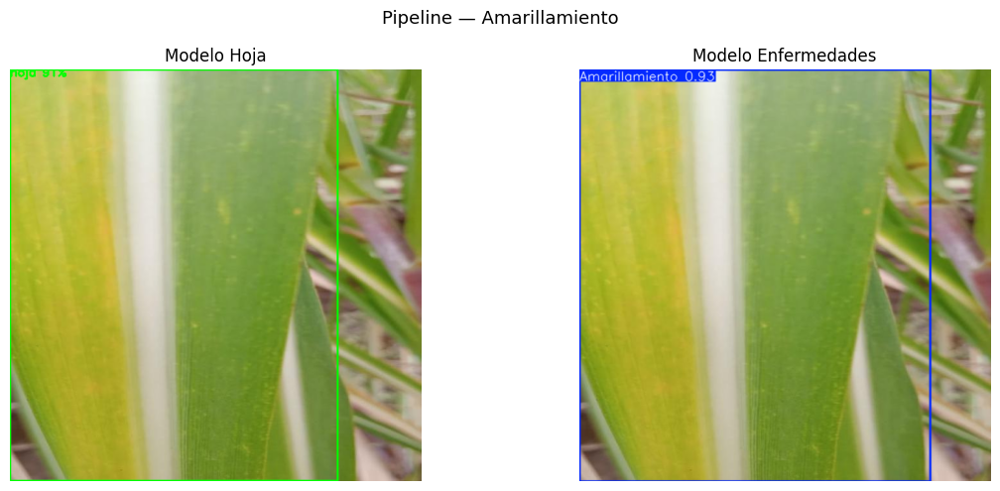

  Amarillamiento: 92.82%
CogolleroAvanzado -> gusano_cogollero-242-_aug_0073_jpg.rf.823da2af7be25fc465806a70cfb688e8.jpg


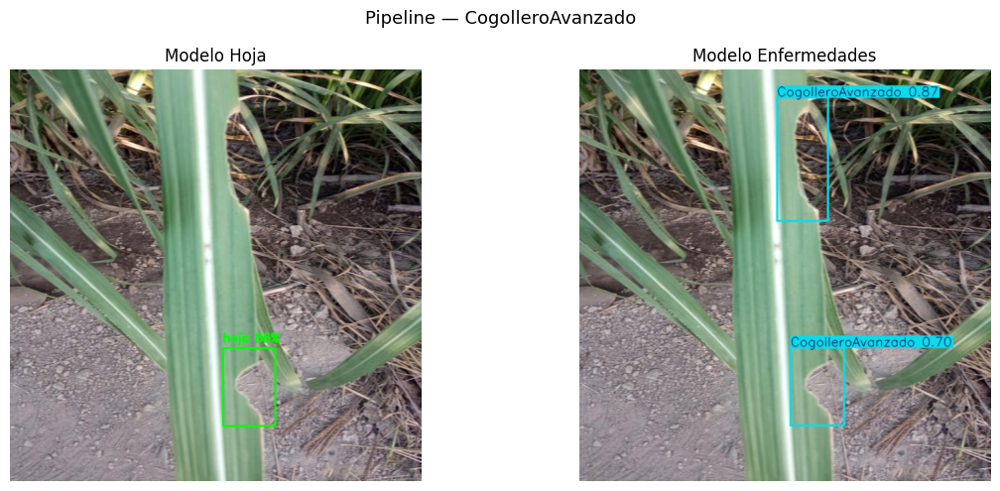

  CogolleroAvanzado: 87.14%
  CogolleroAvanzado: 69.70%
CogolleroInicial -> gusano_cogollero-187-_jpeg.rf.d6f59b7eb4774762932d630728ff289c.jpg


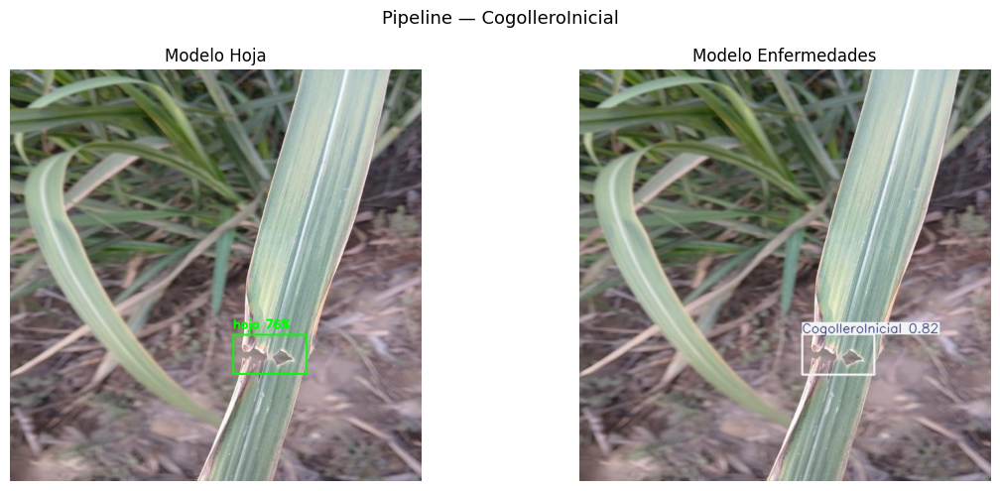

  CogolleroInicial: 81.85%
Mosaico -> mosaic-271-_jpeg.rf.3325bde47e96218cb4c74f91a50609cf.jpg


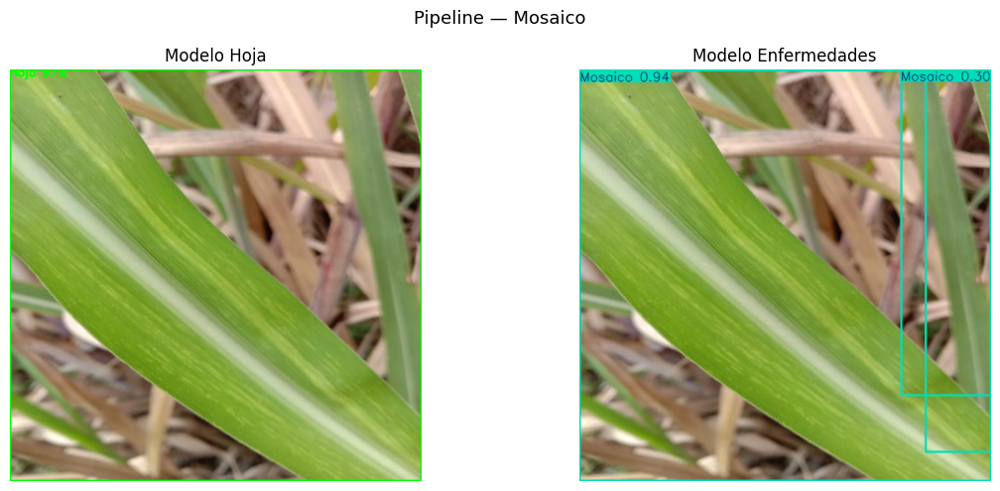

  Mosaico: 93.70%
  Mosaico: 30.22%
  Mosaico: 15.56%
PobredumbreRoja -> redrot-168-_jpeg.rf.8a26addad51ba53e16e9abab84a7c100.jpg


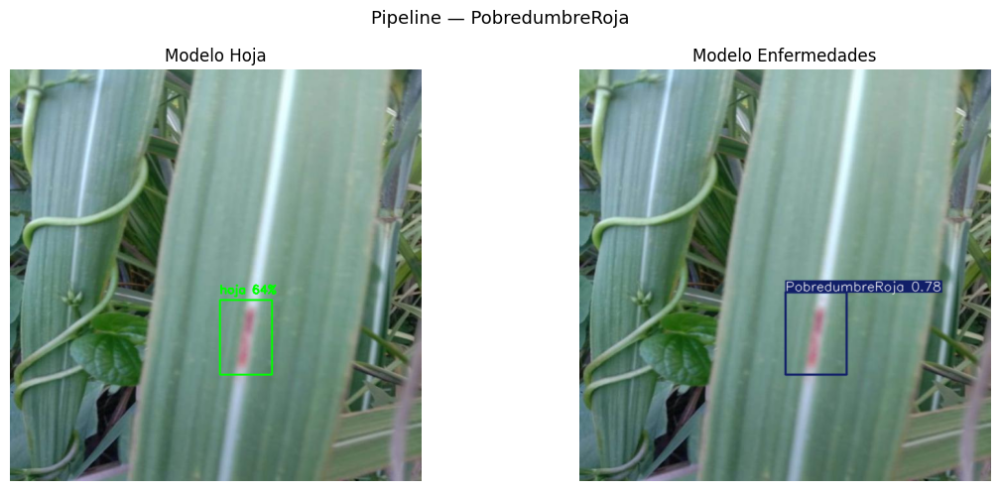

  PobredumbreRoja: 78.42%
Roya -> rust-319-_jpeg.rf.1086436036c469a35147ac4214d67de8.jpg


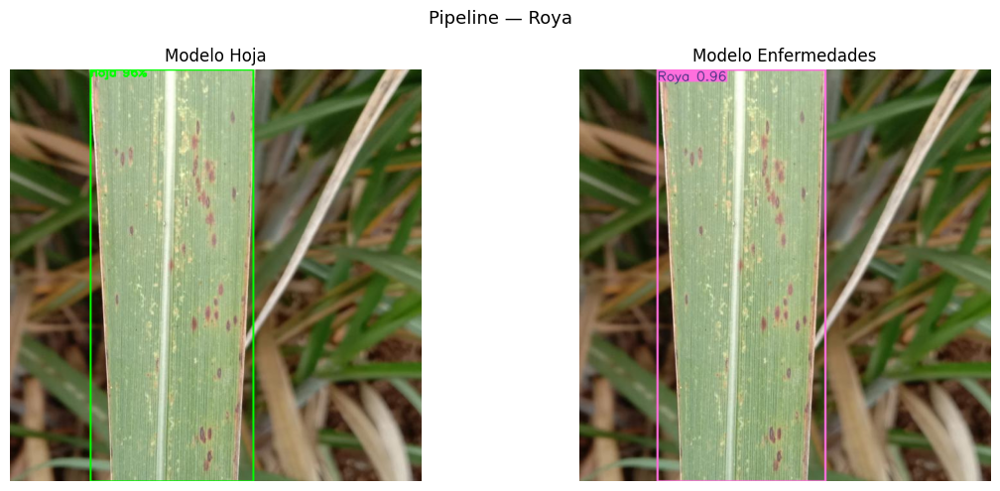

  Roya: 95.92%
Saludable -> healthy-370-_jpeg.rf.7b8201440117fc04056c43f9d7808ee7.jpg


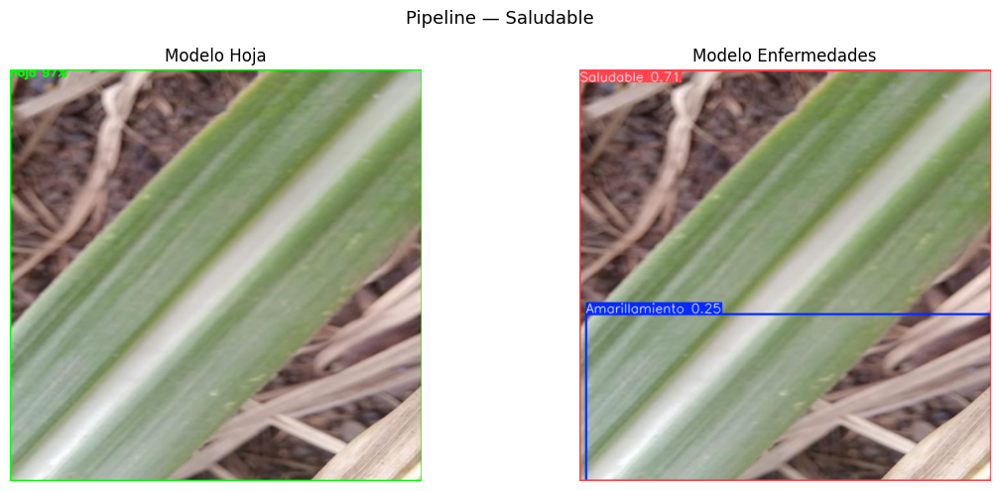

  Saludable: 71.42%
  Amarillamiento: 25.11%

Resultados guardados en Drive.


In [ ]:
import os
import random
import cv2
import matplotlib.pyplot as plt

dataset_path = '/content/dataset_local/test/images'
labels_path = '/content/dataset_local/test/labels'
carpeta_salida = '/content/drive/MyDrive/9no Ciclo/Taller 2/Modelo_DEF5/pipeline_resultados'
os.makedirs(carpeta_salida, exist_ok=True)

extensiones = {'.jpg', '.jpeg', '.png'}
clases = ['Amarillamiento', 'CogolleroAvanzado', 'CogolleroInicial',
          'Mosaico', 'PobredumbreRoja', 'Roya', 'Saludable']
imagenes_por_clase = {c: [] for c in clases}

for img_file in os.listdir(dataset_path):
    if os.path.splitext(img_file)[1].lower() not in extensiones:
        continue
    label_file = os.path.splitext(img_file)[0] + '.txt'
    label_path = os.path.join(labels_path, label_file)
    if not os.path.exists(label_path):
        continue
    with open(label_path, 'r') as f:
        primera_linea = f.readline().strip()
        if not primera_linea:
            continue
        class_id = int(primera_linea.split()[0])
        imagenes_por_clase[clases[class_id]].append(img_file)

random.seed(42)
print('Generando resultados del pipeline - 1 imagen por clase\n')

for nombre_clase in clases:
    imagenes_clase = imagenes_por_clase[nombre_clase]
    if not imagenes_clase:
        print(f'No se encontraron imagenes para: {nombre_clase}')
        continue

    seleccionada = random.choice(imagenes_clase)
    ruta = os.path.join(dataset_path, seleccionada)
    salida = os.path.join(carpeta_salida, f'pipeline_{nombre_clase}.png')
    print(f'{nombre_clase} -> {seleccionada}')

    imagen = cv2.imread(ruta)
    imagen_rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

    resultado1 = model1(imagen, conf=0.45, verbose=False)
    imagen_m1 = imagen_rgb.copy()

    if len(resultado1[0].boxes) == 0:
        print('  No se detecto hoja')
        cv2.putText(imagen_m1, 'Sin deteccion', (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)
    else:
        box = resultado1[0].boxes[0].xyxy[0].cpu().numpy().astype(int)
        cv2.rectangle(imagen_m1, (box[0], box[1]), (box[2], box[3]), (0, 255, 0), 2)
        cv2.putText(imagen_m1, f'hoja {float(resultado1[0].boxes[0].conf):.0%}',
                    (box[0], max(box[1]-10, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

    resultado2 = model2(imagen, conf=0.15, verbose=False)
    img_diag = cv2.cvtColor(resultado2[0].plot(), cv2.COLOR_BGR2RGB)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle(f'Pipeline — {nombre_clase}', fontsize=13)
    axes[0].imshow(imagen_m1)
    axes[0].set_title('Modelo Hoja')
    axes[0].axis('off')
    axes[1].imshow(img_diag)
    axes[1].set_title('Modelo Enfermedades')
    axes[1].axis('off')
    plt.tight_layout()
    plt.savefig(salida, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

    if len(resultado2[0].boxes) == 0:
        print('  No se detecto enfermedad')
    else:
        for box2 in resultado2[0].boxes:
            clase = model2.names[int(box2.cls)]
            conf = float(box2.conf)
            print(f'  {clase}: {conf:.2%}')

print('\nResultados guardados en Drive.')

In [ ]:
import os
import cv2
import numpy as np
from ultralytics import YOLO
from collections import defaultdict

dataset_path = '/content/dataset_local/test/images'
labels_path = '/content/dataset_local/test/labels'

clases = ['Amarillamiento', 'CogolleroAvanzado', 'CogolleroInicial',
          'Mosaico', 'PobredumbreRoja', 'Roya', 'Saludable']

extensiones = {'.jpg', '.jpeg', '.png'}
verdaderos_positivos = defaultdict(int)
falsos_negativos = defaultdict(int)
falsos_positivos = defaultdict(int)
total_por_clase = defaultdict(int)
rechazadas_modelo1 = 0
total_imagenes = 0

for img_file in os.listdir(dataset_path):
    if os.path.splitext(img_file)[1].lower() not in extensiones:
        continue
    label_file = os.path.splitext(img_file)[0] + '.txt'
    label_path = os.path.join(labels_path, label_file)
    if not os.path.exists(label_path):
        continue
    with open(label_path, 'r') as f:
        lineas = f.readlines()
    if not lineas:
        continue

    clases_reales = [clases[int(l.split()[0])] for l in lineas if l.strip()]
    for c in clases_reales:
        total_por_clase[c] += 1

    total_imagenes += 1
    imagen = cv2.imread(os.path.join(dataset_path, img_file))

    resultado1 = model1(imagen, conf=0.20, verbose=False)

    if len(resultado1[0].boxes) == 0:
        rechazadas_modelo1 += 1
        for c in clases_reales:
            falsos_negativos[c] += 1
        continue

    resultado2 = model2(imagen, conf=0.15, verbose=False)
    clases_predichas = [model2.names[int(b.cls)] for b in resultado2[0].boxes]

    for c in clases_reales:
        if c in clases_predichas:
            verdaderos_positivos[c] += 1
        else:
            falsos_negativos[c] += 1

    for c in clases_predichas:
        if c not in clases_reales:
            falsos_positivos[c] += 1

print('=== METRICAS DEL PIPELINE COMPLETO ===\n')
print(f'Total imagenes test: {total_imagenes}')
print(f'Rechazadas por Modelo Hoja: {rechazadas_modelo1} ({rechazadas_modelo1/total_imagenes:.1%})\n')

precisions = []
recalls = []

for c in clases:
    tp = verdaderos_positivos[c]
    fn = falsos_negativos[c]
    fp = falsos_positivos[c]
    total = total_por_clase[c]
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    precisions.append(precision)
    recalls.append(recall)
    print(f'{c}:')
    print(f'  Total real: {total} | TP: {tp} | FN: {fn} | FP: {fp}')
    print(f'  Precision: {precision:.2%} | Recall: {recall:.2%} | F1: {f1:.2%}')

print(f'\n=== GLOBAL ===')
print(f'Precision media: {np.mean(precisions):.2%}')
print(f'Recall medio:    {np.mean(recalls):.2%}')

=== METRICAS DEL PIPELINE COMPLETO ===

Total imagenes test: 253
Rechazadas por Modelo Hoja: 1 (0.4%)

Amarillamiento:
  Total real: 37 | TP: 36 | FN: 1 | FP: 4
  Precision: 90.00% | Recall: 97.30% | F1: 93.51%
CogolleroAvanzado:
  Total real: 51 | TP: 51 | FN: 0 | FP: 8
  Precision: 86.44% | Recall: 100.00% | F1: 92.73%
CogolleroInicial:
  Total real: 75 | TP: 72 | FN: 3 | FP: 5
  Precision: 93.51% | Recall: 96.00% | F1: 94.74%
Mosaico:
  Total real: 25 | TP: 25 | FN: 0 | FP: 3
  Precision: 89.29% | Recall: 100.00% | F1: 94.34%
PobredumbreRoja:
  Total real: 36 | TP: 35 | FN: 1 | FP: 6
  Precision: 85.37% | Recall: 97.22% | F1: 90.91%
Roya:
  Total real: 32 | TP: 31 | FN: 1 | FP: 0
  Precision: 100.00% | Recall: 96.88% | F1: 98.41%
Saludable:
  Total real: 29 | TP: 28 | FN: 1 | FP: 0
  Precision: 100.00% | Recall: 96.55% | F1: 98.25%

=== GLOBAL ===
Precision media: 92.09%
Recall medio:    97.71%


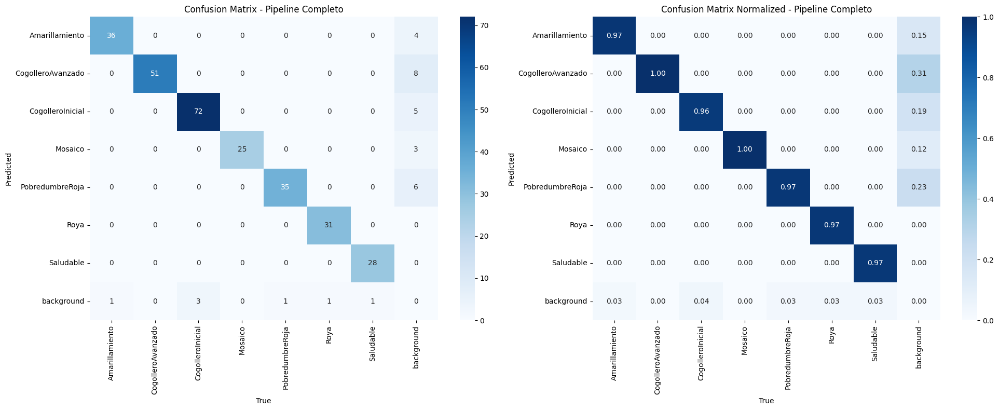

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
import os
import cv2

dataset_path = '/content/dataset_local/test/images'
labels_path = '/content/dataset_local/test/labels'
clases = ['Amarillamiento', 'CogolleroAvanzado', 'CogolleroInicial',
          'Mosaico', 'PobredumbreRoja', 'Roya', 'Saludable']
extensiones = {'.jpg', '.jpeg', '.png'}
n = len(clases)
matriz = np.zeros((n + 1, n + 1), dtype=int)
clase_idx = {c: i for i, c in enumerate(clases)}

for img_file in os.listdir(dataset_path):
    if os.path.splitext(img_file)[1].lower() not in extensiones:
        continue
    label_file = os.path.splitext(img_file)[0] + '.txt'
    label_path = os.path.join(labels_path, label_file)
    if not os.path.exists(label_path):
        continue
    with open(label_path, 'r') as f:
        lineas = f.readlines()
    if not lineas:
        continue
    clases_reales = [clases[int(l.split()[0])] for l in lineas if l.strip()]
    imagen = cv2.imread(os.path.join(dataset_path, img_file))
    resultado1 = model1(imagen, conf=0.20, verbose=False)
    if len(resultado1[0].boxes) == 0:
        for c in clases_reales:
            matriz[n][clase_idx[c]] += 1
        continue
    resultado2 = model2(imagen, conf=0.15, verbose=False)
    clases_predichas = [model2.names[int(b.cls)] for b in resultado2[0].boxes]
    for c_real in clases_reales:
        if c_real in clases_predichas:
            matriz[clase_idx[c_real]][clase_idx[c_real]] += 1
        else:
            matriz[n][clase_idx[c_real]] += 1
    for c_pred in clases_predichas:
        if c_pred not in clases_reales:
            matriz[clase_idx[c_pred]][n] += 1

labels_plot = clases + ['background']
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_plot, yticklabels=labels_plot, ax=axes[0])
axes[0].set_title('Confusion Matrix - Pipeline Completo')
axes[0].set_ylabel('Predicted')
axes[0].set_xlabel('True')

matriz_norm = matriz.astype(float)
col_sums = matriz.sum(axis=0)
col_sums[col_sums == 0] = 1
matriz_norm = matriz_norm / col_sums

sns.heatmap(matriz_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=labels_plot, yticklabels=labels_plot, ax=axes[1])
axes[1].set_title('Confusion Matrix Normalized - Pipeline Completo')
axes[1].set_ylabel('Predicted')
axes[1].set_xlabel('True')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/9no Ciclo/Taller 2/Modelo_DEF5/confusion_matrix_pipeline.png',
            dpi=150, bbox_inches='tight')
plt.show()

# Prueba con Imagenes Reales

PRUEBA CON HOJAS DE CANA

gusano_cogollero-3-_jpeg.rf.09aa0f110be14d131afff7532485d43d.jpg
  Hoja detectada (conf: 81%)
  Diagnostico: CogolleroAvanzado 81%


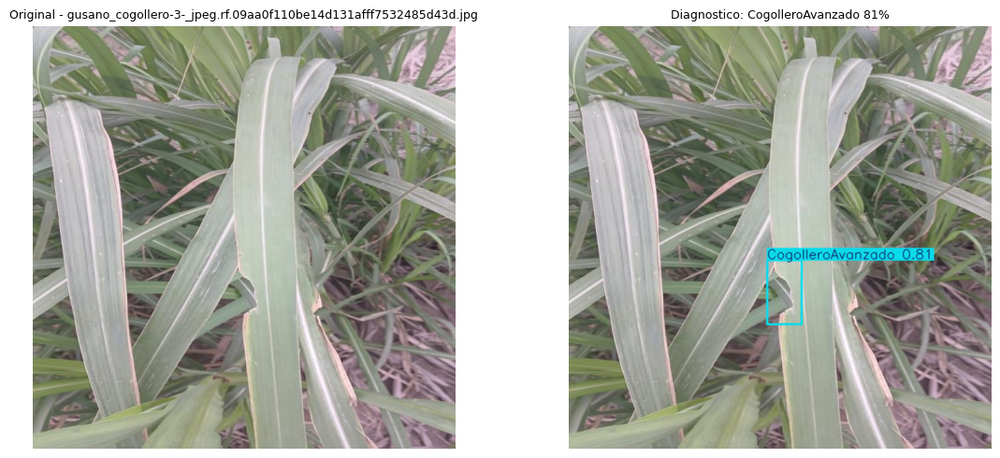


healthy-370-_jpeg.rf.7b8201440117fc04056c43f9d7808ee7.jpg
  Hoja detectada (conf: 97%)
  Diagnostico: Saludable 71%, Amarillamiento 25%


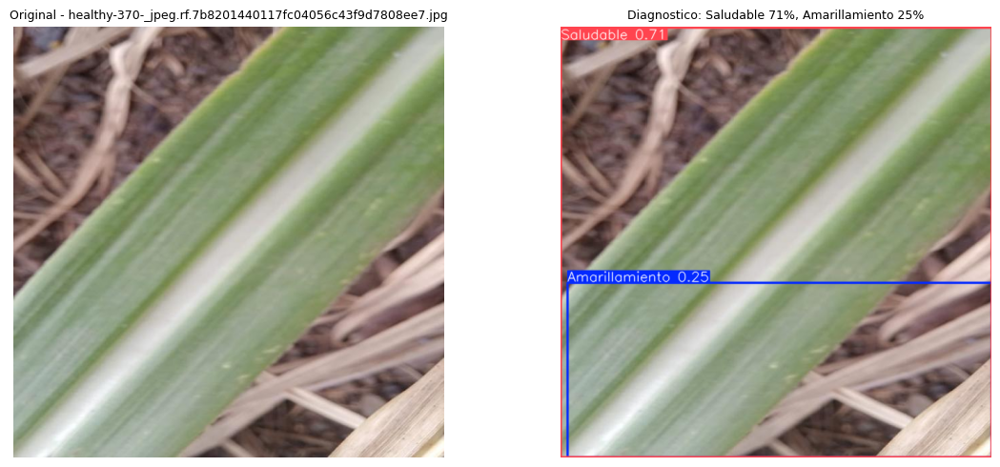


mosaic-69-_jpeg.rf.e37cafb1cfa05ea113b2fb38c6ec8ee1.jpg
  Hoja detectada (conf: 90%)
  Diagnostico: Mosaico 93%


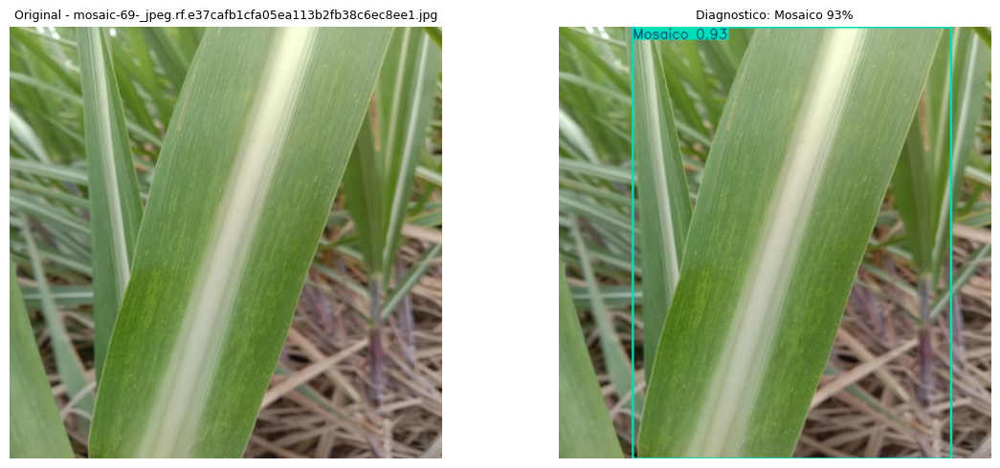


redrot-64-_jpeg.rf.d0493cfd5b8447b68ab80dc6ecb94a5f.jpg
  Hoja detectada (conf: 48%)
  Diagnostico: PobredumbreRoja 21%, PobredumbreRoja 20%


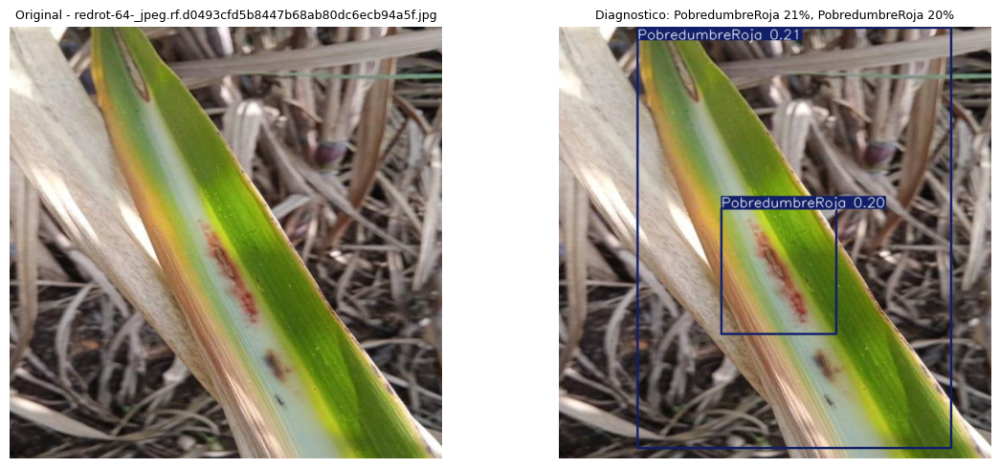


rust-125-_jpeg.rf.d84da3549e3a14583d3be86bd1373358.jpg
  Hoja detectada (conf: 73%)
  Diagnostico: Roya 68%


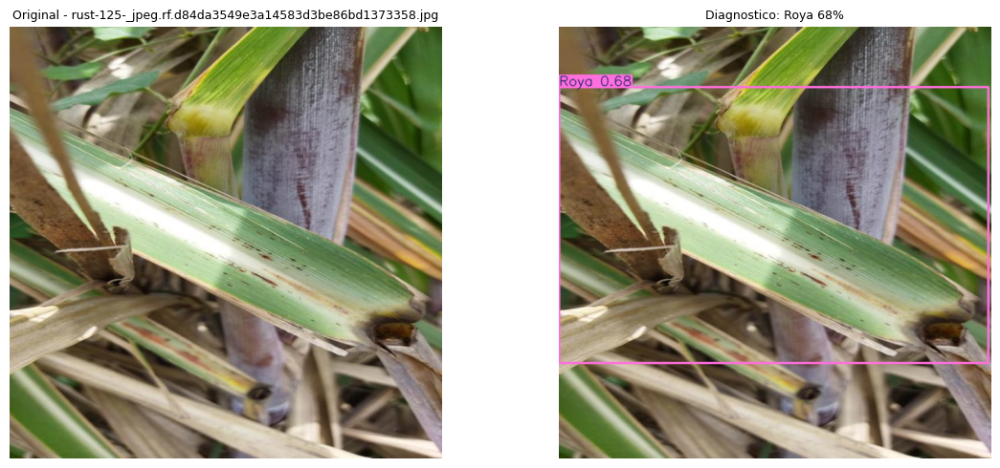


yellow-108-_jpeg.rf.a2f9cffef797f9986376a1fab6662b25.jpg
  Hoja detectada (conf: 90%)
  Diagnostico: Amarillamiento 94%


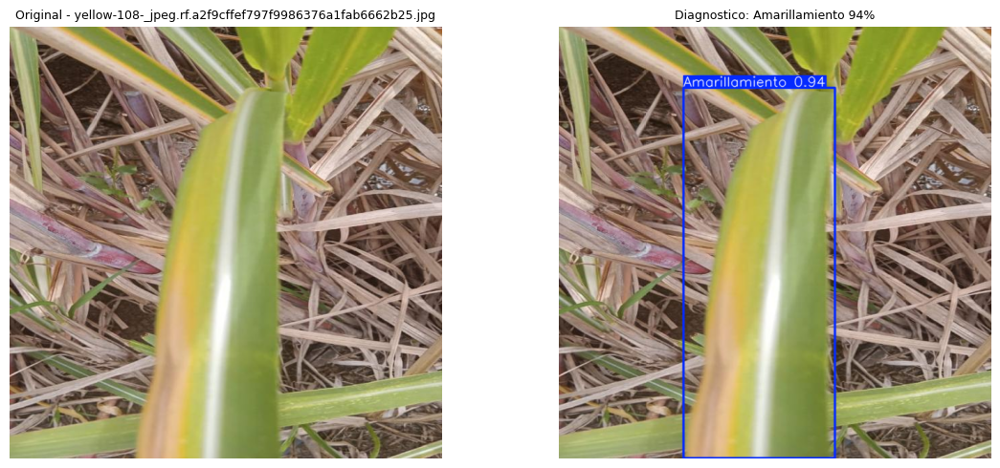


PRUEBA CON IMAGENES NEGATIVAS

WhatsApp Image 2026-06-26 at 9.26.34 PM (1).jpeg
  Rechazada - No es hoja de cana


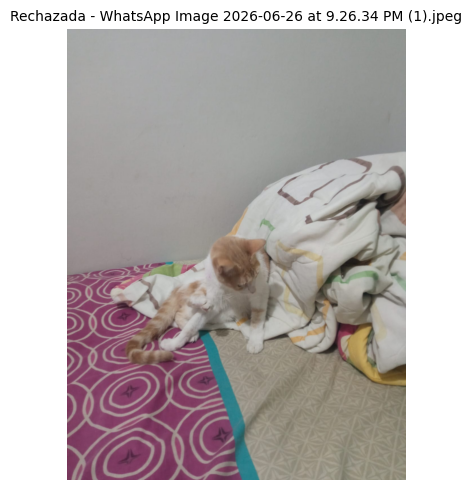


WhatsApp Image 2026-06-26 at 9.26.34 PM (2).jpeg
  Rechazada - No es hoja de cana


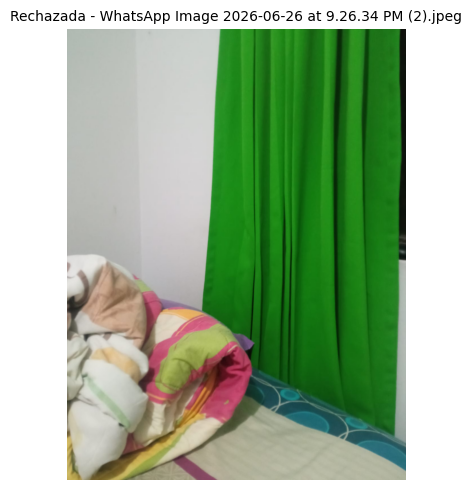


WhatsApp Image 2026-06-26 at 9.26.34 PM (3).jpeg
  Rechazada - No es hoja de cana


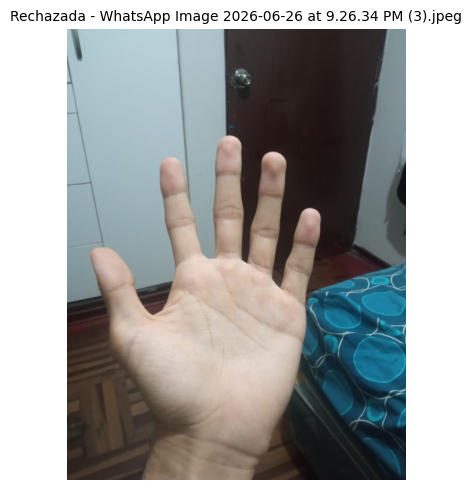


WhatsApp Image 2026-06-26 at 9.26.34 PM (4).jpeg
  Rechazada - No es hoja de cana


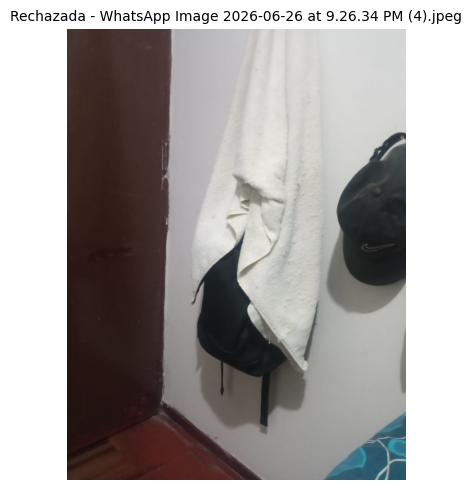


WhatsApp Image 2026-06-26 at 9.26.34 PM.jpeg
  Hoja detectada (conf: 74%)
  Diagnostico: Saludable 47%


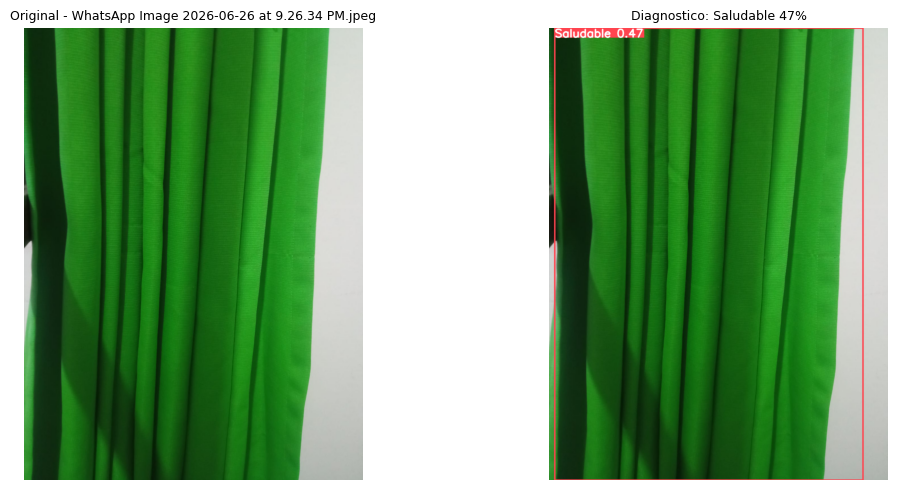


WhatsApp Image 2026-06-26 at 9.26.35 PM (1).jpeg
  Rechazada - No es hoja de cana


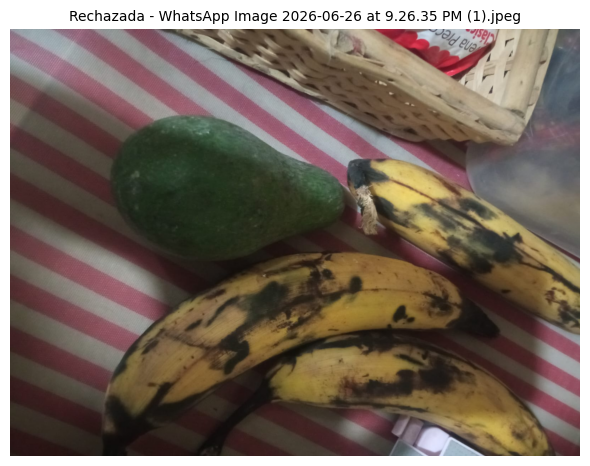


WhatsApp Image 2026-06-26 at 9.26.35 PM (2).jpeg
  Rechazada - No es hoja de cana


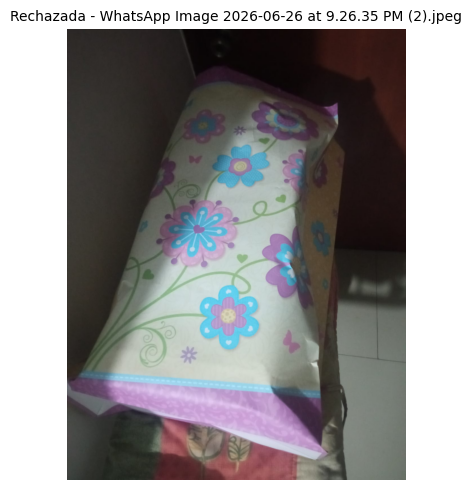


WhatsApp Image 2026-06-26 at 9.26.35 PM (3).jpeg
  Rechazada - No es hoja de cana


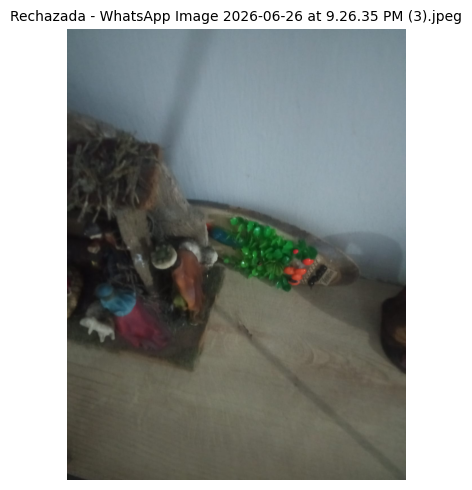


WhatsApp Image 2026-06-26 at 9.26.35 PM.jpeg
  Rechazada - No es hoja de cana


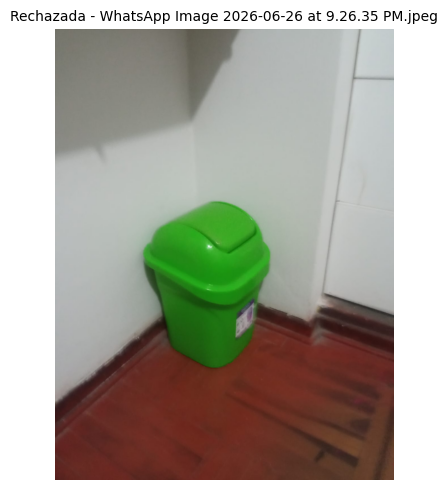


RESUMEN PRUEBA REAL
Hojas detectadas: 6/6 (100%)
Negativos rechazados: 8/9 (89%)


In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

carpeta_hojas = '/content/drive/MyDrive/9no Ciclo/Taller 2/prueba_real/hojas'
carpeta_negativos = '/content/drive/MyDrive/9no Ciclo/Taller 2/prueba_real/negativos'
carpeta_salida = '/content/drive/MyDrive/9no Ciclo/Taller 2/prueba_real/resultados'
os.makedirs(carpeta_salida, exist_ok=True)

extensiones = {'.jpg', '.jpeg', '.png', '.webp'}

def procesar_imagen(ruta, conf_m1=0.20):
    imagen = cv2.imread(ruta)
    if imagen is None:
        print(f'No se pudo leer: {os.path.basename(ruta)}')
        return
    imagen_rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)
    resultado1 = model1(imagen, conf=conf_m1, verbose=False)
    nombre = os.path.basename(ruta)
    nombre_seguro = nombre.replace(' ', '_').replace('(', '').replace(')', '')
    print(f'\n{nombre}')

    if len(resultado1[0].boxes) == 0:
        print('  Rechazada - No es hoja de cana')
        fig, ax = plt.subplots(1, 1, figsize=(6, 5))
        ax.imshow(imagen_rgb)
        ax.set_title(f'Rechazada - {nombre}', fontsize=10)
        ax.axis('off')
        plt.tight_layout()
        plt.savefig(os.path.join(carpeta_salida, f'RECHAZADA_{nombre_seguro}.png'),
                    dpi=150, bbox_inches='tight')
        plt.show()
        plt.close()
        return

    resultado2 = model2(imagen, conf=0.15, verbose=False)
    img_diag = cv2.cvtColor(resultado2[0].plot(), cv2.COLOR_BGR2RGB)
    diagnostico = ', '.join([f"{model2.names[int(b.cls)]} {float(b.conf):.0%}"
                             for b in resultado2[0].boxes]) if len(resultado2[0].boxes) > 0 else 'Sin enfermedad'

    print(f'  Hoja detectada (conf: {float(resultado1[0].boxes[0].conf):.0%})')
    print(f'  Diagnostico: {diagnostico}')

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(imagen_rgb)
    axes[0].set_title(f'Original - {nombre}', fontsize=9)
    axes[0].axis('off')
    axes[1].imshow(img_diag)
    axes[1].set_title(f'Diagnostico: {diagnostico}', fontsize=9)
    axes[1].axis('off')
    plt.tight_layout()
    plt.savefig(os.path.join(carpeta_salida, f'DETECTADA_{nombre_seguro}.png'),
                dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

print('=' * 50)
print('PRUEBA CON HOJAS DE CANA')
print('=' * 50)
hojas_detectadas = 0
total_hojas = 0
for f in sorted(os.listdir(carpeta_hojas)):
    if os.path.splitext(f)[1].lower() in extensiones:
        total_hojas += 1
        ruta = os.path.join(carpeta_hojas, f)
        imagen = cv2.imread(ruta)
        if imagen is not None:
            r1 = model1(imagen, conf=0.20, verbose=False)
            if len(r1[0].boxes) > 0:
                hojas_detectadas += 1
        procesar_imagen(ruta)

print('\n' + '=' * 50)
print('PRUEBA CON IMAGENES NEGATIVAS')
print('=' * 50)
negativos_rechazados = 0
total_negativos = 0
for f in sorted(os.listdir(carpeta_negativos)):
    if os.path.splitext(f)[1].lower() in extensiones:
        total_negativos += 1
        ruta = os.path.join(carpeta_negativos, f)
        imagen = cv2.imread(ruta)
        if imagen is not None:
            r1 = model1(imagen, conf=0.20, verbose=False)
            if len(r1[0].boxes) == 0:
                negativos_rechazados += 1
        procesar_imagen(ruta)

print('\n' + '=' * 50)
print('RESUMEN PRUEBA REAL')
print('=' * 50)
print(f'Hojas detectadas: {hojas_detectadas}/{total_hojas} ({hojas_detectadas/total_hojas:.0%})')
print(f'Negativos rechazados: {negativos_rechazados}/{total_negativos} ({negativos_rechazados/total_negativos:.0%})')

=== MÉTRICAS DEL PIPELINE COMPLETO ===

Total imágenes test: 253
Rechazadas por Modelo Hoja: 1 (0.4%)

Amarillamiento:  P=90.00%  R=97.30%  F1=93.51%
CogolleroAvanzado:  P=86.44%  R=100.00%  F1=92.73%
CogolleroInicial:  P=93.51%  R=96.00%  F1=94.74%
Mosaico:  P=89.29%  R=100.00%  F1=94.34%
PobredumbreRoja:  P=85.37%  R=97.22%  F1=90.91%
Roya:  P=100.00%  R=96.88%  F1=98.41%
Saludable:  P=100.00%  R=96.55%  F1=98.25%

Precision media: 92.09%
Recall medio:    97.71%
F1 medio:        94.70%

=== mAP50 y mAP50-95 DEL PIPELINE ===

Amarillamiento: mAP50=0.9091 (90.9%)  mAP50-95=0.8816 (88.2%)
CogolleroAvanzado: mAP50=0.9033 (90.3%)  mAP50-95=0.5685 (56.9%)
CogolleroInicial: mAP50=0.7595 (75.9%)  mAP50-95=0.3929 (39.3%)
Mosaico: mAP50=0.9091 (90.9%)  mAP50-95=0.8807 (88.1%)
PobredumbreRoja: mAP50=0.5318 (53.2%)  mAP50-95=0.3345 (33.4%)
Roya: mAP50=0.9091 (90.9%)  mAP50-95=0.8434 (84.3%)
Saludable: mAP50=0.9091 (90.9%)  mAP50-95=0.8897 (89.0%)

mAP50 global:    0.8330 (83.30%)
mAP50-95 global

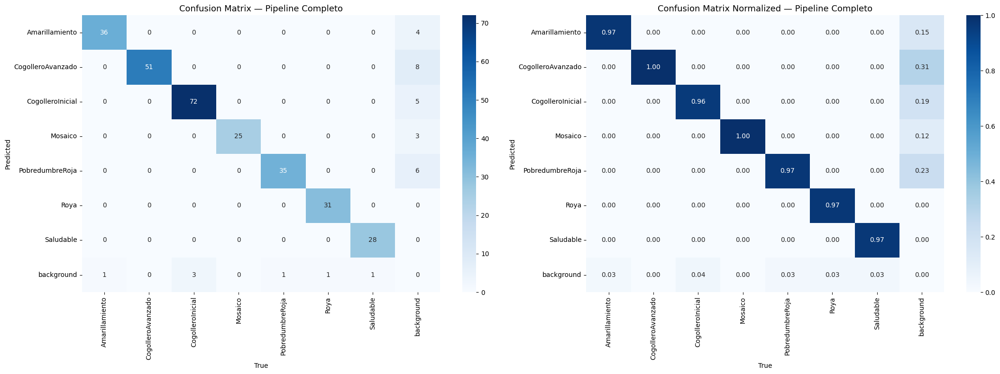

Matriz de confusión guardada.


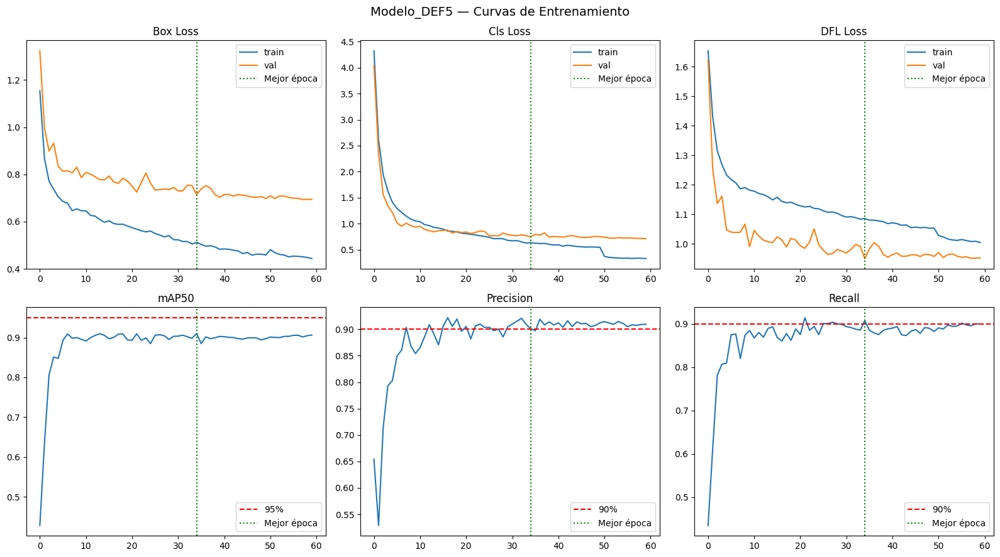

Curvas de entrenamiento guardadas.

Todos los archivos en: /content/drive/MyDrive/9no Ciclo/Taller 2/Modelo_DEF5/reporte_final


In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ultralytics import YOLO
from collections import defaultdict

dataset_path = '/content/dataset_local/test/images'
labels_path = '/content/dataset_local/test/labels'
carpeta_salida = '/content/drive/MyDrive/9no Ciclo/Taller 2/Modelo_DEF5/reporte_final'
os.makedirs(carpeta_salida, exist_ok=True)

clases = ['Amarillamiento', 'CogolleroAvanzado', 'CogolleroInicial',
          'Mosaico', 'PobredumbreRoja', 'Roya', 'Saludable']
extensiones = {'.jpg', '.jpeg', '.png'}
clase_idx = {c: i for i, c in enumerate(clases)}
n = len(clases)

# ── 1. Recolectar predicciones y ground truth ──────────────────────────────
all_predictions = []   # [img_id, cls, conf, x1,y1,x2,y2]
all_ground_truths = [] # [img_id, cls, x1,y1,x2,y2]
matriz = np.zeros((n + 1, n + 1), dtype=int)

verdaderos_positivos = defaultdict(int)
falsos_negativos = defaultdict(int)
falsos_positivos = defaultdict(int)
total_por_clase = defaultdict(int)
rechazadas = 0
total_imgs = 0

for img_id, img_file in enumerate(sorted(os.listdir(dataset_path))):
    if os.path.splitext(img_file)[1].lower() not in extensiones:
        continue
    label_file = os.path.splitext(img_file)[0] + '.txt'
    label_path = os.path.join(labels_path, label_file)
    if not os.path.exists(label_path):
        continue
    with open(label_path, 'r') as f:
        lineas = f.readlines()
    if not lineas:
        continue

    imagen = cv2.imread(os.path.join(dataset_path, img_file))
    h, w = imagen.shape[:2]
    total_imgs += 1

    # Ground truth
    clases_reales = []
    for linea in lineas:
        vals = linea.strip().split()
        if not vals: continue
        cls = int(vals[0])
        cx, cy, bw, bh = float(vals[1]), float(vals[2]), float(vals[3]), float(vals[4])
        x1 = (cx - bw/2) * w; y1 = (cy - bh/2) * h
        x2 = (cx + bw/2) * w; y2 = (cy + bh/2) * h
        all_ground_truths.append([img_id, cls, x1, y1, x2, y2])
        clases_reales.append(clases[cls])
        total_por_clase[clases[cls]] += 1

    # Pipeline
    r1 = model1(imagen, conf=0.20, verbose=False)
    if len(r1[0].boxes) == 0:
        rechazadas += 1
        for c in clases_reales:
            falsos_negativos[c] += 1
            matriz[n][clase_idx[c]] += 1
        continue

    r2 = model2(imagen, conf=0.15, verbose=False)
    clases_predichas = [model2.names[int(b.cls)] for b in r2[0].boxes]

    for box in r2[0].boxes:
        cls = int(box.cls); conf = float(box.conf)
        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
        all_predictions.append([img_id, cls, conf, x1, y1, x2, y2])

    for c in clases_reales:
        if c in clases_predichas:
            verdaderos_positivos[c] += 1
            matriz[clase_idx[c]][clase_idx[c]] += 1
        else:
            falsos_negativos[c] += 1
            matriz[n][clase_idx[c]] += 1

    for c in clases_predichas:
        if c not in clases_reales:
            falsos_positivos[c] += 1
            matriz[clase_idx[c]][n] += 1

# ── 2. Precision / Recall / F1 por clase ──────────────────────────────────
print("=== MÉTRICAS DEL PIPELINE COMPLETO ===\n")
print(f"Total imágenes test: {total_imgs}")
print(f"Rechazadas por Modelo Hoja: {rechazadas} ({rechazadas/total_imgs:.1%})\n")

precisions, recalls, f1s = [], [], []
for c in clases:
    tp = verdaderos_positivos[c]
    fn = falsos_negativos[c]
    fp = falsos_positivos[c]
    p = tp / (tp + fp) if (tp + fp) > 0 else 0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2*p*r/(p+r) if (p+r) > 0 else 0
    precisions.append(p); recalls.append(r); f1s.append(f1)
    print(f"{c}:  P={p:.2%}  R={r:.2%}  F1={f1:.2%}")

print(f"\nPrecision media: {np.mean(precisions):.2%}")
print(f"Recall medio:    {np.mean(recalls):.2%}")
print(f"F1 medio:        {np.mean(f1s):.2%}")

# ── 3. mAP50 con IoU=0.5 ──────────────────────────────────────────────────
def calcular_ap50(preds, gts, cls_id, iou_thresh=0.5):
    cls_preds = sorted([p for p in preds if p[1]==cls_id], key=lambda x:-x[2])
    cls_gts   = [g for g in gts if g[1]==cls_id]
    if not cls_gts: return 0.0
    matched = set()
    tp_list, fp_list = [], []
    for pred in cls_preds:
        px1,py1,px2,py2 = pred[3],pred[4],pred[5],pred[6]
        best_iou, best_idx = 0, -1
        for i, gt in enumerate(cls_gts):
            if gt[0]!=pred[0] or i in matched: continue
            gx1,gy1,gx2,gy2 = gt[2],gt[3],gt[4],gt[5]
            ix1=max(px1,gx1); iy1=max(py1,gy1)
            ix2=min(px2,gx2); iy2=min(py2,gy2)
            inter=max(0,ix2-ix1)*max(0,iy2-iy1)
            union=(px2-px1)*(py2-py1)+(gx2-gx1)*(gy2-gy1)-inter
            iou=inter/union if union>0 else 0
            if iou>best_iou: best_iou=iou; best_idx=i
        if best_iou>=iou_thresh and best_idx>=0:
            tp_list.append(1); fp_list.append(0); matched.add(best_idx)
        else:
            tp_list.append(0); fp_list.append(1)
    tp_cum=np.cumsum(tp_list); fp_cum=np.cumsum(fp_list)
    rec=tp_cum/len(cls_gts); prec=tp_cum/(tp_cum+fp_cum)
    ap=sum(np.max(prec[rec>=t]) if any(rec>=t) else 0 for t in np.arange(0,1.1,0.1))/11
    return ap

def calcular_ap(preds, gts, cls_id, iou_thresh):
    return calcular_ap50(preds, gts, cls_id, iou_thresh)

print("\n=== mAP50 y mAP50-95 DEL PIPELINE ===\n")
aps50, aps5095 = [], []
for i, c in enumerate(clases):
    ap50 = calcular_ap(all_predictions, all_ground_truths, i, 0.5)
    ap5095 = np.mean([calcular_ap(all_predictions, all_ground_truths, i, t)
                      for t in np.arange(0.5, 1.0, 0.05)])
    aps50.append(ap50); aps5095.append(ap5095)
    print(f"{c}: mAP50={ap50:.4f} ({ap50*100:.1f}%)  mAP50-95={ap5095:.4f} ({ap5095*100:.1f}%)")

print(f"\nmAP50 global:    {np.mean(aps50):.4f} ({np.mean(aps50)*100:.2f}%)")
print(f"mAP50-95 global: {np.mean(aps5095):.4f} ({np.mean(aps5095)*100:.2f}%)")

# ── 4. Matriz de confusión ────────────────────────────────────────────────
labels_plot = clases + ['background']
fig, axes = plt.subplots(1, 2, figsize=(22, 8))

sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_plot, yticklabels=labels_plot, ax=axes[0])
axes[0].set_title('Confusion Matrix — Pipeline Completo', fontsize=13)
axes[0].set_ylabel('Predicted'); axes[0].set_xlabel('True')

col_sums = matriz.sum(axis=0); col_sums[col_sums==0] = 1
matriz_norm = matriz.astype(float) / col_sums
sns.heatmap(matriz_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=labels_plot, yticklabels=labels_plot, ax=axes[1])
axes[1].set_title('Confusion Matrix Normalized — Pipeline Completo', fontsize=13)
axes[1].set_ylabel('Predicted'); axes[1].set_xlabel('True')

plt.tight_layout()
plt.savefig(f'{carpeta_salida}/confusion_matrix_pipeline.png', dpi=150, bbox_inches='tight')
plt.show()
print("Matriz de confusión guardada.")

# ── 5. Curvas Loss/mAP desde results.csv ─────────────────────────────────
import pandas as pd
df = pd.read_csv(f'{results_path}/results.csv')
df.columns = df.columns.str.strip()
mejor_epoca = df['metrics/mAP50(B)'].idxmax()

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('Modelo_DEF5 — Curvas de Entrenamiento', fontsize=14)

axes[0,0].plot(df['train/box_loss'], label='train'); axes[0,0].plot(df['val/box_loss'], label='val')
axes[0,0].axvline(mejor_epoca, color='g', linestyle=':', label='Mejor época')
axes[0,0].set_title('Box Loss'); axes[0,0].legend()

axes[0,1].plot(df['train/cls_loss'], label='train'); axes[0,1].plot(df['val/cls_loss'], label='val')
axes[0,1].axvline(mejor_epoca, color='g', linestyle=':', label='Mejor época')
axes[0,1].set_title('Cls Loss'); axes[0,1].legend()

axes[0,2].plot(df['train/dfl_loss'], label='train'); axes[0,2].plot(df['val/dfl_loss'], label='val')
axes[0,2].axvline(mejor_epoca, color='g', linestyle=':', label='Mejor época')
axes[0,2].set_title('DFL Loss'); axes[0,2].legend()

axes[1,0].plot(df['metrics/mAP50(B)'])
axes[1,0].axhline(0.95, color='r', linestyle='--', label='95%')
axes[1,0].axvline(mejor_epoca, color='g', linestyle=':', label='Mejor época')
axes[1,0].set_title('mAP50'); axes[1,0].legend()

axes[1,1].plot(df['metrics/precision(B)'])
axes[1,1].axhline(0.90, color='r', linestyle='--', label='90%')
axes[1,1].axvline(mejor_epoca, color='g', linestyle=':', label='Mejor época')
axes[1,1].set_title('Precision'); axes[1,1].legend()

axes[1,2].plot(df['metrics/recall(B)'])
axes[1,2].axhline(0.90, color='r', linestyle='--', label='90%')
axes[1,2].axvline(mejor_epoca, color='g', linestyle=':', label='Mejor época')
axes[1,2].set_title('Recall'); axes[1,2].legend()

plt.tight_layout()
plt.savefig(f'{carpeta_salida}/curvas_entrenamiento_DEF5.png', dpi=150, bbox_inches='tight')
plt.show()
print("Curvas de entrenamiento guardadas.")
print(f"\nTodos los archivos en: {carpeta_salida}")

In [ ]:
import pandas as pd

# Modelo Enfermedades
results_path = '/content/drive/MyDrive/9no Ciclo/Taller 2/Modelo_DEF5'
df = pd.read_csv(f'{results_path}/results.csv')
df.columns = df.columns.str.strip()
mejor_epoca = df['metrics/mAP50(B)'].idxmax()
print(f"Modelo_DEF5 — mejor época: {mejor_epoca + 1} → checkpoint: epoch{mejor_epoca}.pt")

# Modelo Hoja
results_path_leaf = '/content/drive/MyDrive/9no Ciclo/Taller 2/Modelo_Hoja_v2'
df_leaf = pd.read_csv(f'{results_path_leaf}/results.csv')
df_leaf.columns = df_leaf.columns.str.strip()
mejor_epoca_leaf = df_leaf['metrics/mAP50(B)'].idxmax()
print(f"Modelo_Hoja_v2 — mejor época: {mejor_epoca_leaf + 1} → checkpoint: epoch{mejor_epoca_leaf}.pt")

Modelo_DEF5 — mejor época: 35 → checkpoint: epoch34.pt
Modelo_Hoja_v2 — mejor época: 48 → checkpoint: epoch47.pt


Imágenes de PobredumbreRoja encontradas: 34

OK (hoja 70%): redrot-260-_jpeg.rf.7fded44cb47fe8c5d001818cc8a6e896.jpg → Amarillamiento 65%, PobredumbreRoja 44%, PobredumbreRoja 19%


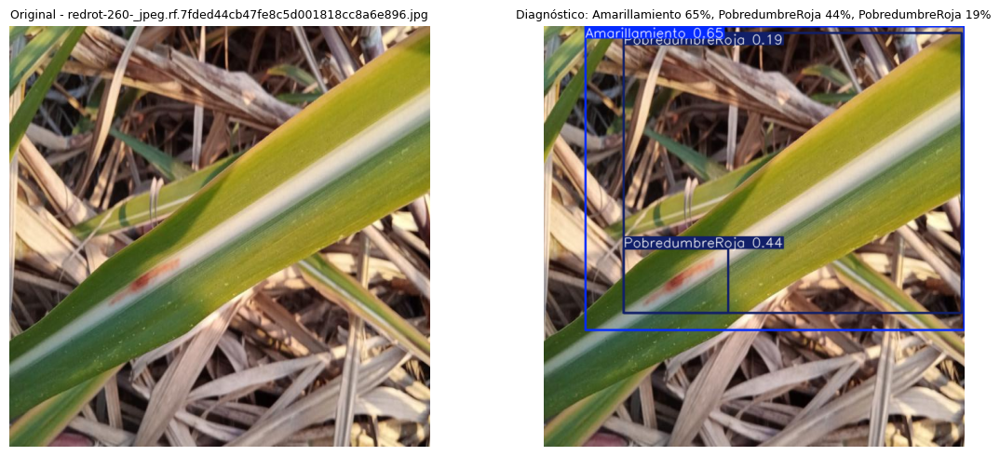


OK (hoja 67%): redrot-234-_jpeg.rf.caae1306de5185ce75bfbf76b0e46eeb.jpg → PobredumbreRoja 77%


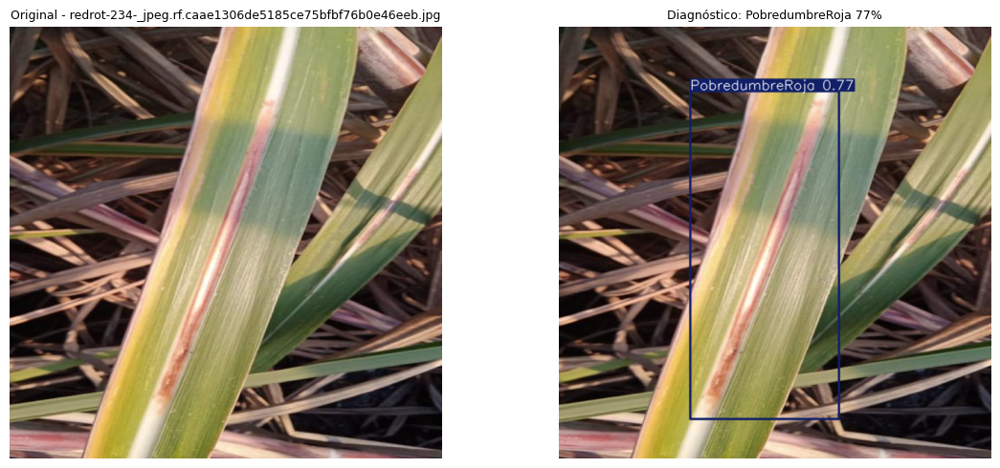


OK (hoja 60%): redrot-50-_jpeg.rf.3573a9388f6d55d9a3ee0bf23f60ea00.jpg → PobredumbreRoja 76%, PobredumbreRoja 53%


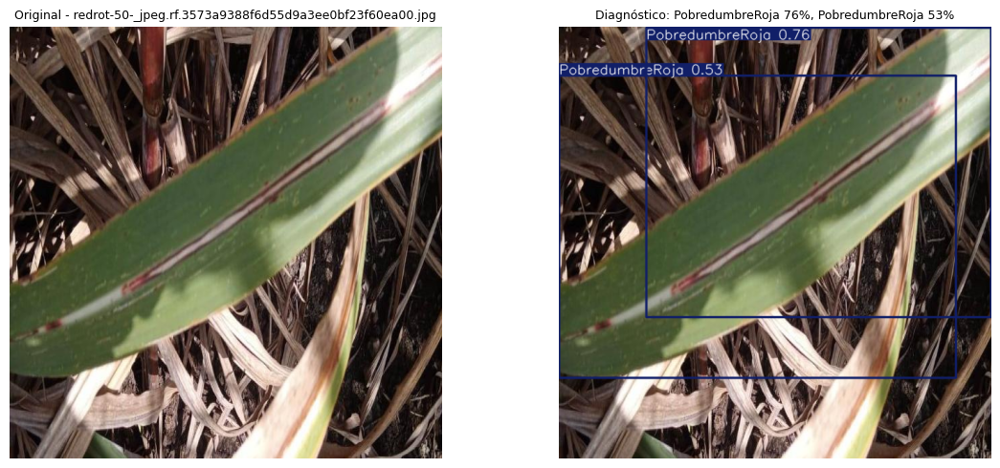


OK (hoja 48%): redrot-9-_jpeg.rf.b257acab1286a59bd069cb320455b3c1.jpg → PobredumbreRoja 28%


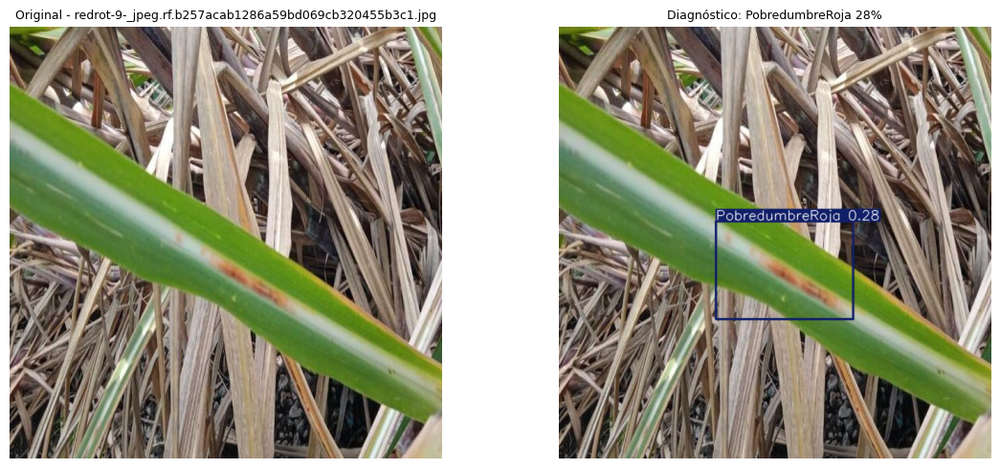


OK (hoja 81%): redrot-236-_jpeg.rf.2cf055728b200d81d8e1c6b55021d2a1.jpg → PobredumbreRoja 89%


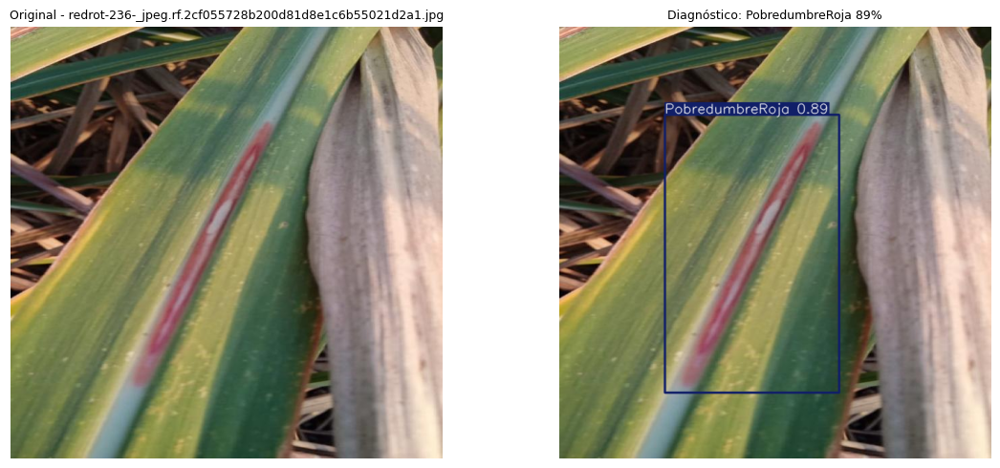


OK (hoja 76%): redrot-380-_jpeg.rf.3bdaa53890f7eccbcd45a93f10db23d6.jpg → PobredumbreRoja 82%, PobredumbreRoja 22%


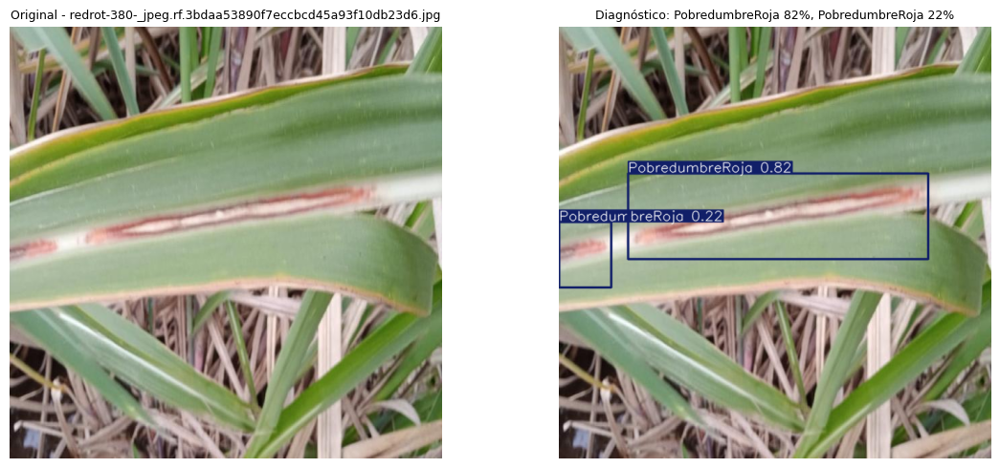


OK (hoja 72%): redrot-2-_jpeg.rf.ff52b9f601bd246122b97846570e8aaa.jpg → PobredumbreRoja 91%


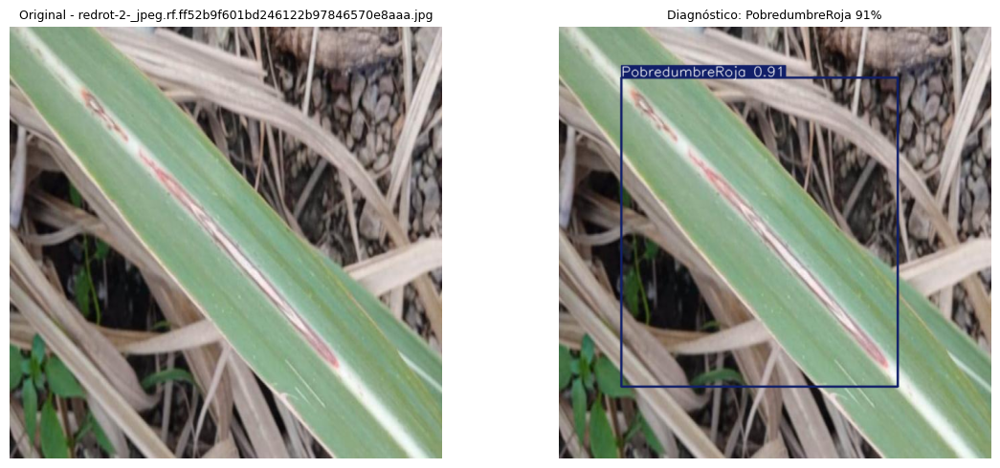


OK (hoja 70%): redrot-144-_jpeg.rf.7aed50e440ec004189a616c02de181fd.jpg → PobredumbreRoja 88%


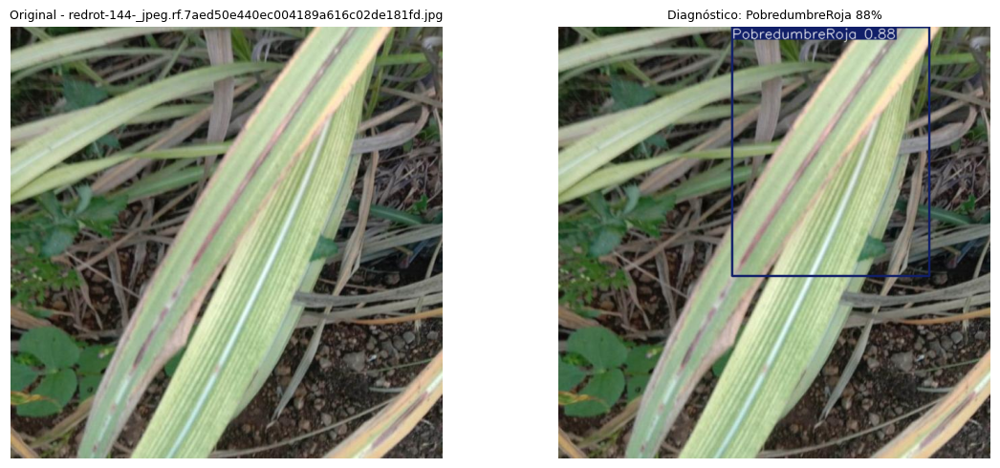


OK (hoja 58%): redrot-62-_jpeg.rf.7b60772beedbc82b19c60aa9db2101b1.jpg → PobredumbreRoja 82%


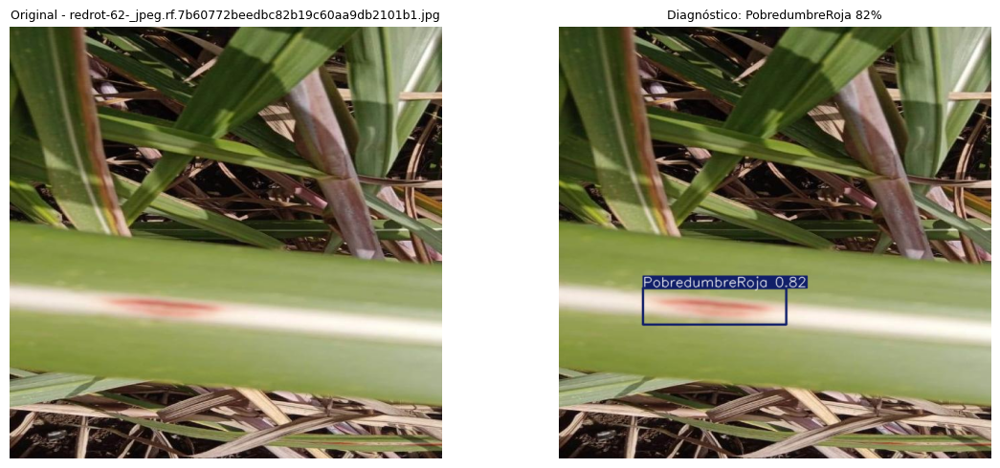


OK (hoja 65%): redrot-331-_jpeg.rf.32e6f6b4112dd7689d271cf5d6c2a48a.jpg → PobredumbreRoja 72%


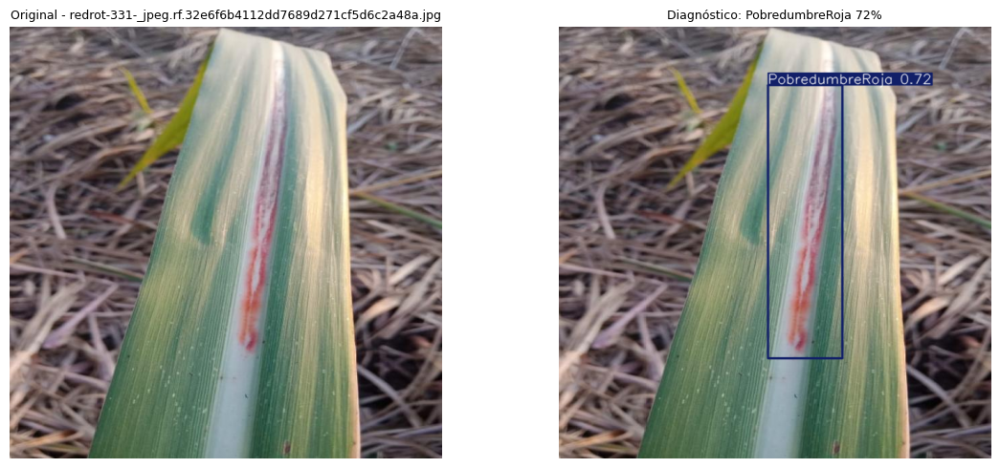


OK (hoja 69%): redrot-25-_jpeg.rf.aad1f691e321acccb61a4775b46821f2.jpg → PobredumbreRoja 78%


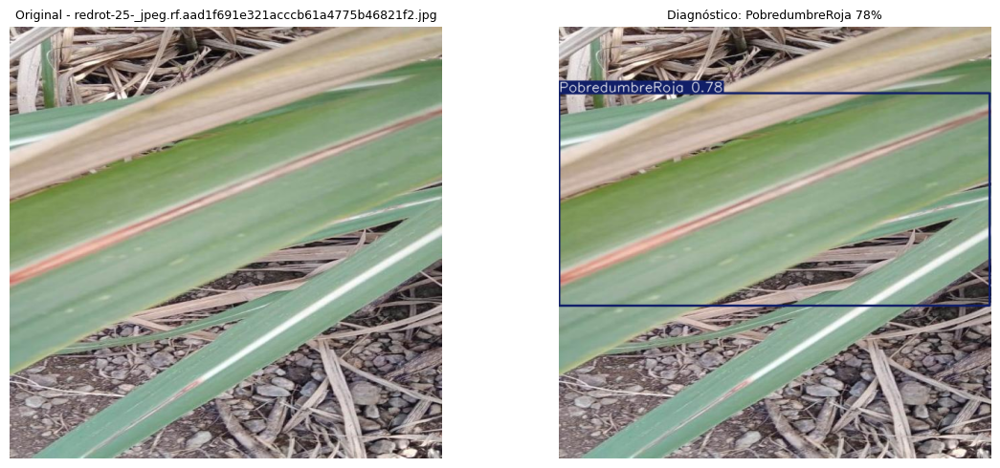


OK (hoja 79%): redrot-155-_jpeg.rf.d3eb9397d8c3cabee5d2cbef354268c7.jpg → PobredumbreRoja 85%


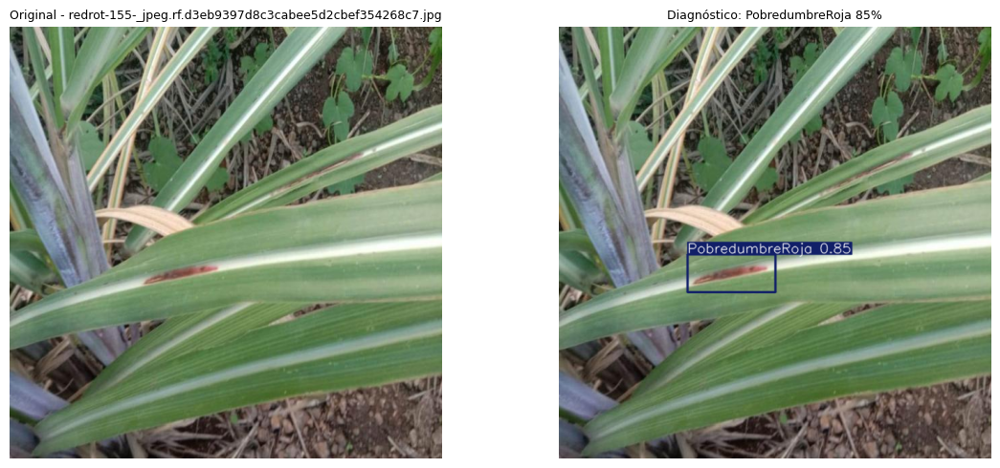


OK (hoja 66%): redrot-210-_jpeg.rf.ee700ae35583f9a091f7361a39dc2585.jpg → PobredumbreRoja 69%


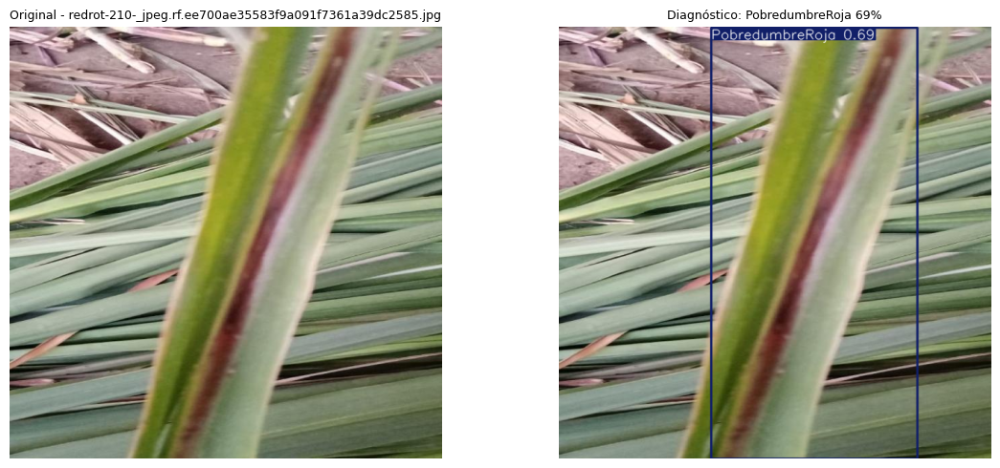


OK (hoja 64%): redrot-168-_jpeg.rf.8a26addad51ba53e16e9abab84a7c100.jpg → PobredumbreRoja 78%


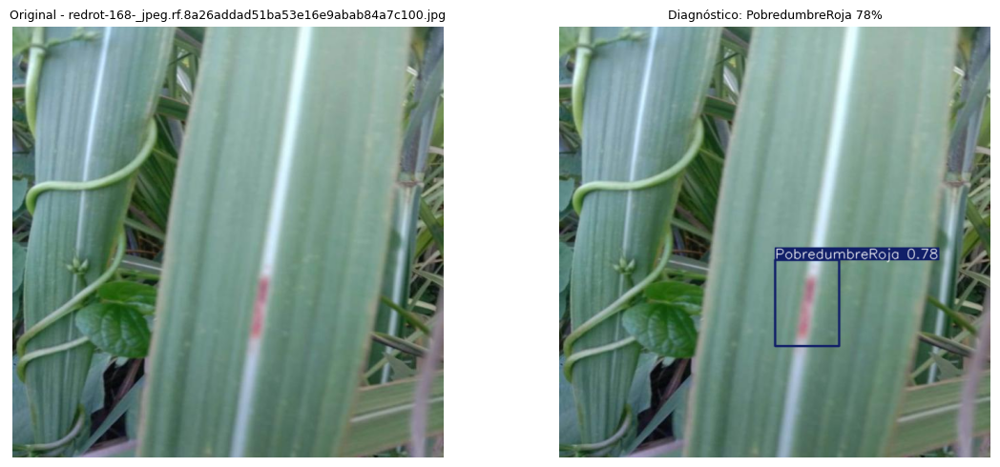


OK (hoja 57%): redrot-141-_jpeg.rf.768fcf82e1cc017498c88992abd38a17.jpg → PobredumbreRoja 59%, PobredumbreRoja 58%, PobredumbreRoja 48%, PobredumbreRoja 28%, PobredumbreRoja 26%


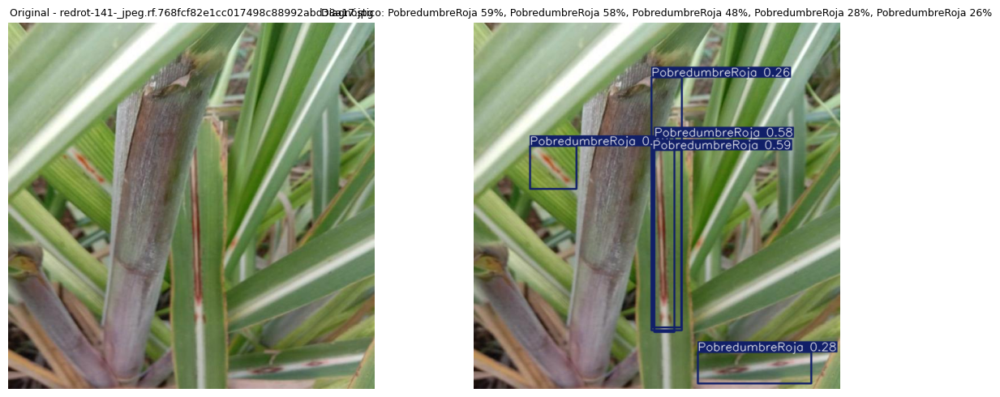


OK (hoja 67%): redrot-78-_jpeg.rf.0eba28c8881200cb79f22dbd2a4a9b0a.jpg → PobredumbreRoja 80%, PobredumbreRoja 35%


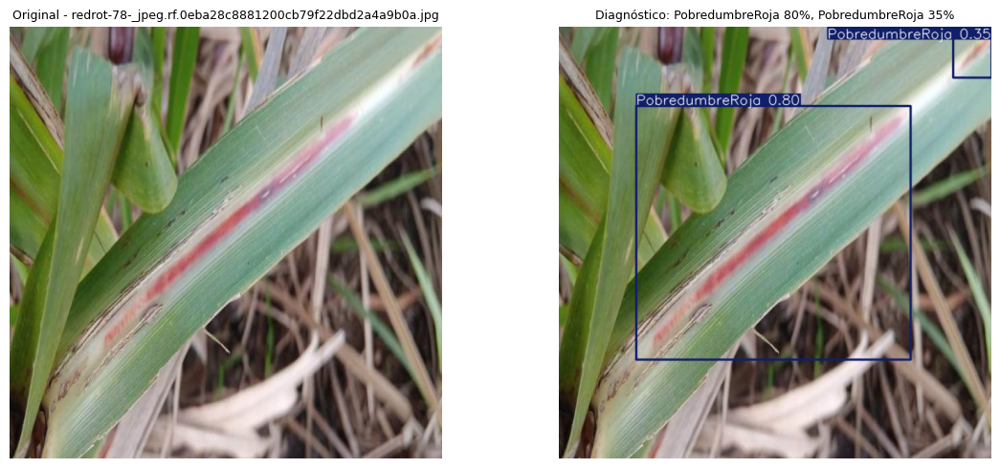


OK (hoja 78%): redrot-402-_jpeg.rf.7d578f4742b385ec403460f4d05efaab.jpg → PobredumbreRoja 90%


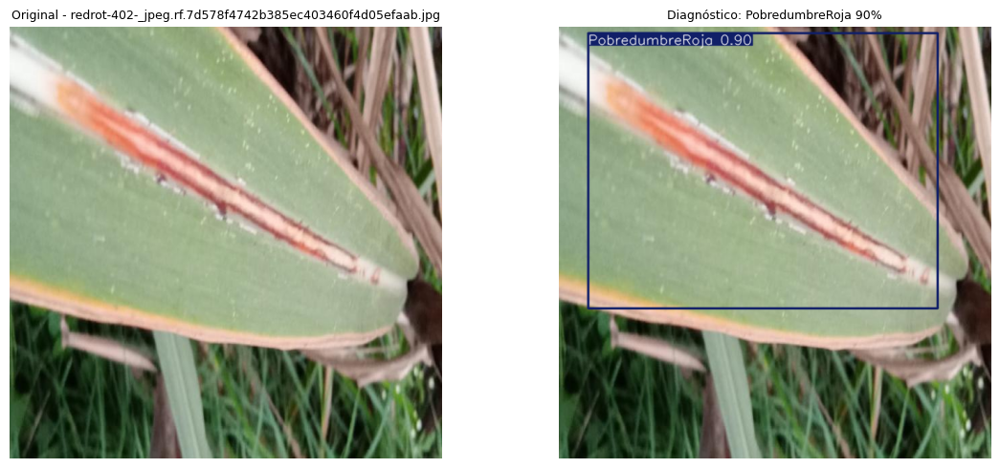


OK (hoja 30%): redrot-172-_jpeg.rf.4c082a7f9b9369c329f8fc6ed02d6bd8.jpg → PobredumbreRoja 47%, PobredumbreRoja 31%, PobredumbreRoja 27%


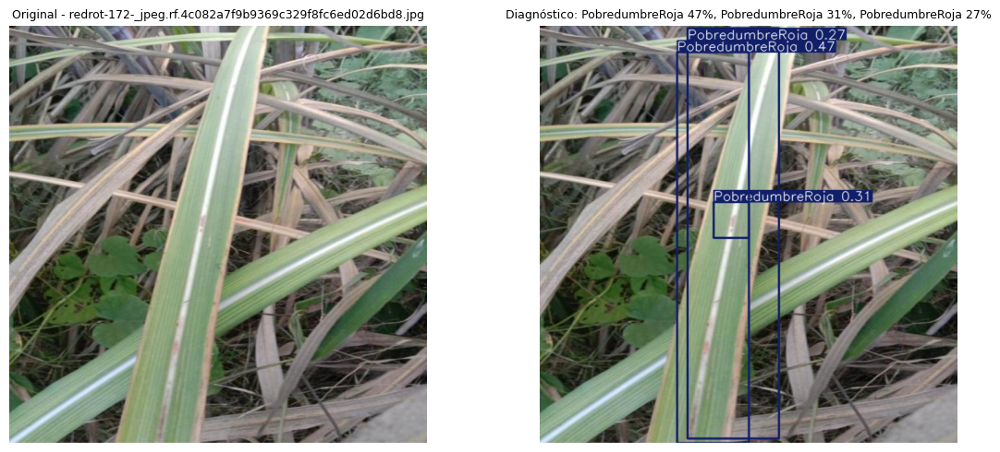


OK (hoja 68%): redrot-186-_jpeg.rf.e593803ca1656ca8ff0a5359d3fd0efa.jpg → PobredumbreRoja 75%


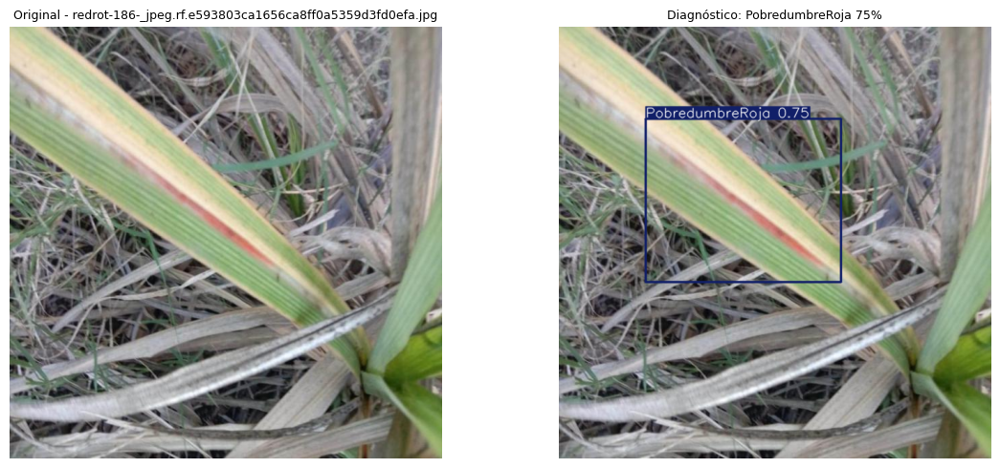


OK (hoja 73%): redrot-176-_jpeg.rf.a75ad4debfe8956679b854e03d9f1627.jpg → PobredumbreRoja 88%, PobredumbreRoja 38%, PobredumbreRoja 18%


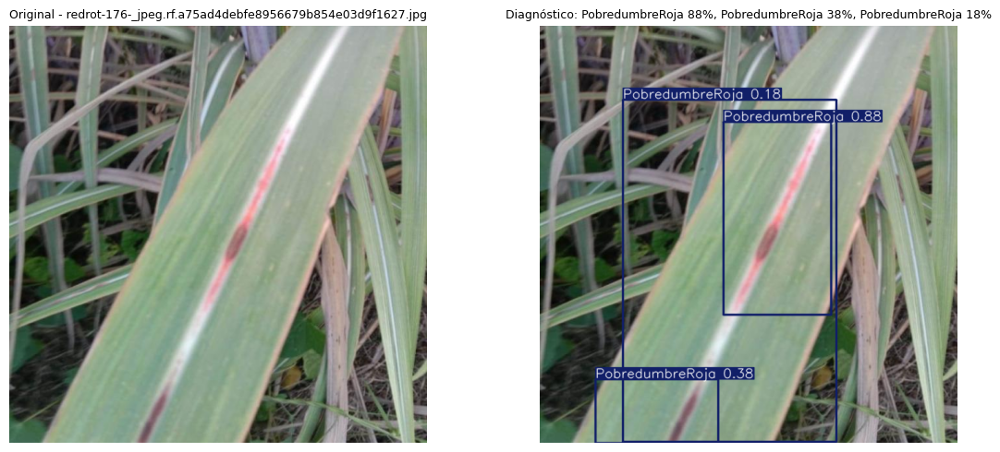


Detectadas por Modelo Hoja: 20/20
Rechazadas por Modelo Hoja: 0/20


In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
import random

carpeta_redrot = '/content/drive/MyDrive/9no Ciclo/Taller 2/Sugarcane Modelo.v8-datasetdefinitivo_v2.yolov8/test/images'
carpeta_labels = '/content/drive/MyDrive/9no Ciclo/Taller 2/Sugarcane Modelo.v8-datasetdefinitivo_v2.yolov8/test/labels'
carpeta_salida = '/content/drive/MyDrive/9no Ciclo/Taller 2/prueba_redrot'
os.makedirs(carpeta_salida, exist_ok=True)

# Filtrar imágenes de PobredumbreRoja (clase 4)
imagenes_redrot = []
for label_file in os.listdir(carpeta_labels):
    if not label_file.endswith('.txt'):
        continue
    ruta_label = os.path.join(carpeta_labels, label_file)
    with open(ruta_label, 'r') as f:
        contenido = f.read().strip()
    if contenido and any(line.startswith('4 ') for line in contenido.split('\n')):
        img_name = label_file.replace('.txt', '.jpg')
        ruta_img = os.path.join(carpeta_redrot, img_name)
        if os.path.exists(ruta_img):
            imagenes_redrot.append(ruta_img)

print(f"Imágenes de PobredumbreRoja encontradas: {len(imagenes_redrot)}")

muestra = random.sample(imagenes_redrot, min(20, len(imagenes_redrot)))

detectadas = 0
rechazadas = 0

for ruta in muestra:
    imagen = cv2.imread(ruta)
    imagen_rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)
    nombre = os.path.basename(ruta)
    nombre_seguro = nombre.replace(' ', '_').replace('(', '').replace(')', '')

    r1 = model1(imagen, conf=0.20, verbose=False)

    if len(r1[0].boxes) == 0:
        rechazadas += 1
        print(f"\nRECHAZADA por Modelo Hoja: {nombre}")

        fig, ax = plt.subplots(1, 1, figsize=(6, 5))
        ax.imshow(imagen_rgb)
        ax.set_title(f'RECHAZADA - {nombre}', fontsize=9, color='red')
        ax.axis('off')
        plt.tight_layout()
        plt.savefig(os.path.join(carpeta_salida, f'RECHAZADA_{nombre_seguro}.png'),
                    dpi=150, bbox_inches='tight')
        plt.show()
        plt.close()
        continue

    detectadas += 1
    conf_hoja = float(r1[0].boxes[0].conf)
    r2 = model2(imagen, conf=0.15, verbose=False)
    img_diag = cv2.cvtColor(r2[0].plot(), cv2.COLOR_BGR2RGB)
    diagnostico = ', '.join([
        f"{model2.names[int(b.cls)]} {float(b.conf):.0%}"
        for b in r2[0].boxes
    ]) if len(r2[0].boxes) > 0 else 'Sin detección'

    print(f"\nOK (hoja {conf_hoja:.0%}): {nombre} → {diagnostico}")

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(imagen_rgb)
    axes[0].set_title(f'Original - {nombre}', fontsize=9)
    axes[0].axis('off')
    axes[1].imshow(img_diag)
    axes[1].set_title(f'Diagnóstico: {diagnostico}', fontsize=9)
    axes[1].axis('off')
    plt.tight_layout()
    plt.savefig(os.path.join(carpeta_salida, f'DETECTADA_{nombre_seguro}.png'),
                dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

print(f"\n{'='*50}")
print(f"Detectadas por Modelo Hoja: {detectadas}/{len(muestra)}")
print(f"Rechazadas por Modelo Hoja: {rechazadas}/{len(muestra)}")